# Function 3

<b> Description of the Sample Application:</b> You’re working on a drug discovery project, testing combinations of three compounds to create a new medicine.
Each experiment is stored in initial_inputs.npy as a 3D array, where each row lists the amounts of the three compounds used. After each experiment, you record the number of adverse reactions, stored in initial_outputs.npy as a 1D array.
Your goal is to minimise side effects; in this competition, it is framed as maximisation by optimising a transformed output (e.g. the negative of side effects). # Final Status (After Round 13)

| Item | Value |
|---|---|
| Final best observed output | **-3.116137e-03** at **(0.411697, 0.562131, 0.417491)** (Week 11) |
| Result of the final query (Week 13) | -1.650908e-02 at (0.463877, 0.612656, 0.417300), no improvement on the best |
| Improvement over the best of the initial 15 points (-3.4835e-02) | ~11x (error rate down from 3.48% to 0.31%) |
| Improvement over the previous best (Week 9, -3.963e-03) | ~1.3x |
| Versus the reference best for Function 3 (-7.172e-03) | ~2.3x better (smaller adverse-reaction score) |
| Queries used | 13 of 13 (this file needs **no further query submission**) |
| Data points | 15 initial + 13 weekly = **Dependent Files:** 
- `initial_inputs.npy`
- `initial_outputs.npy`
- `plotting_utils.py` <br><br>
**Libraries Used:** <br>
`numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`ikit-learn`.



## Change Log

| Date | Week | Changes Made |
|---|---|---|
| 22/07/2026 | Week 1 | 1. Initial Version with 10 Data Point |
| 22/07/2026 | Week 2 | 1. Added Change Log and Progress Log.<br>2. Added new data point. |
| 29/07/2026 | Week 3 | 1. Added Week 2 feedback data point.<br>2. Refactored the repeated fit-acquire logic into one consolidated bayesian_optimization_step() function.<br>4. Lowered beta further (1.0 -> 0.6), leaning further towards exploitation.<br>5. Added a convergence plot and parallel-coordinates plot using plotting_utils.<br>6. Re-ran the second-optimum check on the larger dataset. |
| 05/08/2026 | Week 4 | 1. Amended Week 3 input and output data points.<br>2. Re-ran the consolidated bayesian_optimization_step() on 18 points (kernel re-selected via LOO CV).<br>3. Lowered beta further (0.6 -> 0.4), continuing the exploitation-leaning trend. |
| 12/08/2026 | Week 5 | 1. **Fixed a critical data bug**: Y_w3_new_point was incorrectly 0.5572213082937378 (should be -0.05549717617041605) - corrected at source.<br>2. Added Week 4 feedback data point.<br>3. Added a calibration check comparing each week's GP prediction (fit without that point) against the actual observed outcome.<br>4. **Strategy pivot**: switched from global candidate search to a local search bounded around the current best point, since 3 of 4 queried points clustered in the same corner region without beating the incumbent best, which itself is supported by only one observation. |
| 02/09/2026 | Week 6 | 1. Added Week 5 feedback data point, **new record best** (y = -0.0325, beating the prior -0.0348), confirming the Week 5 local-search pivot worked.<br>2. **Strategy change**: widened the local search bound (+/-0.2 -> +/-0.4) and raised beta back up (0.3 -> 0.8), re-introducing more exploration |
| 09/09/2026 | Week 7 | 1. Added Week 6 feedback data point (y = -0.0549, worse than the Week 5 best - the widened corner search did not improve on it).<br>2. Re-ran kernel selection via LOO CV (Matern selected, 0.084 vs RBF's 0.090) and inspected the **learned length-scales**: compound_1 and compound_2 are pinned at the upper bound (approx. 10, i.e. the model treats them as nearly irrelevant), while compound_3's length-scale is short (approx. 0.12). It is the dominant driver of the outcome.<br>3. **Strategy change**: moved from a symmetric local search box to a **feature-aware search** - compound_3 tightly bounded to its empirically good band ([0.25, 0.50], where every one of our best results has landed), while compound_1/compound_2 are left essentially unconstrained ([0,1]), since the fitted model shows they contribute little. |
| 17/09/2026 | Week 8 | 1. Appended Week 7 feedback data point (y = -0.0679 - worse than the Week 5 best, despite compound_3 being right in the previously-identified 'good band').<br>2. **Retracted the Week 7 length-scale conclusion**: compound_1/compound_2 are NOT irrelevant. Week 7's query pushed them to an extreme (0.98, 1.00) while keeping compound_3 near-identical to Week 5's, and scored notably worse. This falsifies the "compound_1/2 barely matter" reading of the length-scales, which was premature given how little of the compound_1/compound_2 space had actually been tested at the time.<br>3. **Strategy change**: reverted from the unconstrained feature-aware search back to a tight local search (+/-0.15) centred on the actual best point, keeping compound_1/2 moderate (as in Week 5) rather than exploring extremely corner points. |
| 23/09/2026 | Week 9 | 1. Added Week 8 feedback data point, a new best-point (y = -0.0125, more than double the previous best of -0.0325).<br>2. Kernel's length-scales still show compound_1/2 as "nearly irrelevant" even though Week 8's result depended on them being moderate rather than extreme.<br>3. **Strategy**: continued exploitation, tightening the local search further (+/-0.15 -> +/-0.08, beta 0.3 -> 0.2) around the new best point, since the moderate-region hypothesis has now been reinforced. |
| 30/09/2026 | Week 10 | 1. Added Week 9 feedback data point (y = -0.003963, **new best**, more than 3x better than Week 8's -0.0125.<br>2. Kernel re-selected via LOO CV on the full 24-point dataset - Matern retained (RMSE 0.0803 vs RBF's 0.0836).<br>3. **Strategy**: continued exploitation, tightening the local search further (+/-0.08 -> +/-0.05, beta 0.2 -> 0.15) around the new best point. |
| 05/10/2026 | Week 11 | 1. Added Week 10 feedback data point (y = -0.010100, **worse** than Week 9's best of -0.003963 - the first regression since Week 7, though it still lands inside the same moderate-compound-1/2 neighbourhood as every recent best point, well within the GP's predicted uncertainty at that spot.<br>2. Kernel re-selected via LOO CV on the full 25-point dataset - Matern retained (RMSE 0.0750 vs RBF's 0.0816).<br>3. Added a **clustering analysis** (KMeans, k=2 and k=3) over the 10 weekly queried points to formally identify the "good region" the search has converged on vs. the discarded corner excursions, directly informing this week's reflection on clusters/patterns.<br>4. **Strategy**: kept the local search box the same size (+/-0.05) rather than tightening further, since the regression suggests we may be near a noise floor / flat region rather than a clear slope - but raised beta slightly (0.15 -> 0.2) to hedge with a touch more exploration within the box. |
| 14/10/2026 | Week 12 | 1. Added Week 11 feedback data point (y = -0.003116, a **new best**, narrowly ahead of Week 9's -0.003963). It was queried near the lower edge of the Week 11 search box, so the hedge (beta 0.15 -> 0.2) did no harm.<br>2. Kernel re-selected via LOO CV on the full 26-point dataset - Matern retained (RMSE 0.0736 vs RBF's 0.0800).<br>3. **Noise check**: the fitted WhiteKernel implies an observation-noise std of roughly 0.007, the same size as the gaps between the Week 9, 10 and 11 results (-0.0040, -0.0101, -0.0031). The GP's posterior mean at all three points is about -0.0073, so the raw best is partly luck and should not be over-trusted.<br>4. **Strategy**: box size kept at +/-0.05, but it is now re-centred on the new best (it drifts down the compound_1/compound_2 diagonal), and beta lowered 0.2 -> 0.1 ahead of the final query. Added two diagnostics: a beta-sensitivity check (the chosen point does not change for any beta from 0 to 0.5) and a box-edge check (the suggested point sits on the box edge, i.e. it is a probe along the trend, not an interior optimum).<br>5. Added a **PCA analysis** (scree, loadings, PC1-PC2 projection of all points) to show that compound_1 and compound_2 behave as one redundant axis. |
| 24/10/2026 | Week 13 (final) | 1. Added Week 12 feedback data point (y = -0.020220): **much worse** than the Week 11 best (-0.003116), about 0.013 below the GP's prediction (-0.0071 +/- 0.0079) and roughly 1.6x the fitted noise std (0.008). The Week 12 probe down the compound_1/compound_2 diagonal (compound_1 0.37) therefore fell off the good ridge.<br>2. Kernel re-selected via LOO CV on the full 27-point dataset - Matern retained (RMSE 0.0749 vs RBF's 0.0818). Length-scales are unchanged (10, 10, 0.1), so the GP is still almost flat in compound_1/2 and its posterior-mean maximiser is therefore a weak guide for compound_1/2.<br>3. **Strategy change for the final query**: stop trusting the GP to choose compound_1/2 and use the evidence directly. The five consecutive queries that share compound_3 of about 0.415-0.418 (Weeks 8-12) lie on one ridge in compound_1/2; a quadratic fit of y along that ridge (PC1 direction) has a peak at compound_1 of about 0.46, stable under leave-one-out and bootstrap checks. compound_3 is then set by the GP. beta = 0 (pure exploitation, no hedging) since no query remains afterwards.<br>4. Added a ridge-fit visualisation, extended the dashboard and calibration check to Week 12 and made the final point deterministic. |
| 31/10/2026 | Final | 1. Added the Week 13 feedback point: queried [0.463877, 0.612656, 0.4173] => y = -0.016509. No further query is needed, so this is the closing update.<br>2. **The final query did not improve on the best.** Best observed remains Week 11 (-0.003116 at [0.411697, 0.562131, 0.417491]). The result was about 0.014 below the ridge-quadratic's prediction (-0.0024) and about 0.006 below the GP's (-0.0101), i.e. roughly 1.8 and 0.8 times the fitted noise std (0.008).<br>3. The final-query cell now refits a GP on the first 27 points only, so it still reproduces the point that was actually submitted after the Week 13 data is appended.<br>4. Added a Week 13 outcome analysis (prediction vs actual, post-hoc ridge refit, noise comparison), extended calibration, scatter plots, convergence plot and the portal cell to Week 13, and rebuilt the final dashboard (panel 1 now shows predicted vs actual for the final query; panel 2 overlays each week's observed result). |

## Progress Log

| Round | # Data Points | Method / Acquisition | beta (kappa) | Best x (compound_1, compound_2, compound_3) | Best y | Notes |
|---|---|---|---|---|---|---|
| Week 1 | 15 | GP-UCB | 2.5 (exploration-heavy) | [0.4926, 0.6116, 0.3402] (unchanged - query point was new) | -0.0348 | Queried [0.989736, 0.937592, 0.849609] => y = -0.0498. Uncertainty-driven pick near domain edge |
| Week 2 | 16 | GP-UCB, kernel re-selected via LOO CV | 1.0 (exploitation-leaning) | [0.4926, 0.6116, 0.3402] (still current best) | -0.0348 | Appended Week 1 feedback, cross-validated kernel choice (Matern selected), lowered beta, checked for a second optimum |
| Week 3 | 17 | GP-UCB via consolidated bayesian_optimization_step(), kernel re-selected via LOO CV | 0.6 (further exploitation-leaning) | [0.4926, 0.6116, 0.3402] (still current best) | -0.0348 | Appended Week 2 feedback: queried [0.130658, 0.076877, 0.000068] => y = -0.1731. Matern selected again via LOO CV. Second-optimum check still flags a distant high-mean region |
| Week 4 | 18 | GP-UCB via bayesian_optimization_step(), kernel re-selected via LOO CV | 0.4 (further exploitation-leaning) | [0.4926, 0.6116, 0.3402] (still current best) | -0.0348 | Appended Week 3 feedback (corrected): queried [0.990706, 0.795157, 0.087796] => y = -0.0555 (close to, but still short of, the incumbent best). RBF and Matern LOO scores nearly tied (0.0903 vs 0.0903); Matern selected again, marginally |
| Week 5 | 19 | Local GP-UCB (bounded +/-0.2 around current best), kernel re-selected via LOO CV | 0.3 (exploitation, local) | [0.4926, 0.6116, 0.3402] (still current best) | -0.0348 | Fixed a corrupted Week 3 output value. Appended Week 4 feedback: queried [0.996345, 0.961156, 0.025695] => y = -0.0825 (worse than best). Pivoted to a local search bounded around the current best, since 3 of 4 queries had clustered in the same corner without beating it |
| Week 6 | 20 | Widened local GP-UCB (bounded +/-0.4), kernel re-selected via LOO CV | 0.8 (exploration re-introduced) | [0.6831, 0.8068, 0.3921] (**new best**) | -0.0325 | Appended Week 5 feedback: queried [0.683102, 0.806806, 0.392104] => y = -0.0325, a **new record best**. A cohort colleague's benchmark reached y = -0.0048, notably better, suggesting our local neighbourhood may still be a local, not global, optimum. Widened the search bound and raised beta to hedge |
| Week 7 | 21 | Feature-aware GP-UCB (compound_3 tightly bounded, compound_1/2 unconstrained), kernel re-selected via LOO CV | 0.3 (exploitation, feature-aware) | [0.6831, 0.8068, 0.3921] (still current best) | -0.0325 | Appended Week 6 feedback: queried [0.981431, 0.950647, 0.511337] => y = -0.0549 (worse than best, but well-calibrated - GP predicted -0.0524, error only -0.0026). Learned kernel length-scales showed compound_1/2 are nearly irrelevant (pinned at upper bound) while compound_3 is dominant (short length-scale ~0.12) with an apparent good band around 0.34-0.39. Pivoted the search to exploit this directly |
| Week 8 | 22 | Local GP-UCB (tight box +/-0.15 around actual best point), kernel re-selected via LOO CV | 0.3 (exploitation) | [0.6831, 0.8068, 0.3921] (still current best) | -0.0325 | Appended Week 7 feedback: queried [0.977494, 0.997588, 0.372098] => y = -0.0679 (worse than best, despite compound_3 landing right in the previously-identified good band). This falsifies Week 7's conclusion that compound_1/2 barely matter - reverted to a tight local search keeping compound_1/2 moderate, as in the Week 5 best point || Week 9 | 23 | Tighter local GP-UCB (+/-0.08 around new best), kernel re-selected via LOO CV | 0.2 (exploitation) | [0.5388, 0.6829, 0.4153] (**major new best**) | -0.0125 | Appended Week 8 feedback: queried [0.538784, 0.682926, 0.415306] => y = -0.0125, more than double the previous best, closing most of the gap to the colleague's earlier benchmark (-0.0048). GP under-predicted how good this would be (predicted -0.0285, actual -0.0125, error +0.0161) - a bigger jump than expected. Length-scales still show compound_1/2 as near-irrelevant despite evidence they matter at the extremes - flagged as an open modelling caveat. Tightened the local search further to refine around this new best |
| Week 10 | 24 | Tighter local GP-UCB (+/-0.05 around new best), kernel re-selected via LOO CV | 0.15 (exploitation) | [0.4591, 0.6087, 0.4167] (**major new best**) | -0.0040 | Appended Week 9 feedback: queried [0.459096, 0.608722, 0.416672] => y = -0.003963, more than 3x better than the Week 8 best and now better than the colleague's earlier -0.0048 benchmark. Calibration error kept shrinking (Week 8: -0.0053, Week 9: +0.0059) - the GP is tracking this region increasingly well. Tightened the local search further to refine around this new best; two queries remain (Week 11, then the final Week 12 submission) |
| Week 11 | 25 | Local GP-UCB (box kept at +/-0.05, beta raised slightly), kernel re-selected via LOO CV | 0.2 (exploitation, slightly hedged) | [0.4591, 0.6087, 0.4167] (still current best - Week 10 did not improve on it) | -0.0040 | Appended Week 10 feedback: queried [0.410604, 0.568193, 0.418252] => y = -0.010100, worse than the Week 9 best (first regression since Week 7). GP had predicted -0.0025 +/- 0.0033 - a miss, but the point still sits well inside the KMeans-identified "good cluster" (weeks 5, 8, 9, 10; mean y = -0.0148) that is clearly separated from the discarded corner-exploration cluster (weeks 1,3,4,6,7; mean y = -0.0621) and the Week 2 outlier (y = -0.1731). Kept the search box the same size, raised beta slightly to hedge, since one query remains after this before the final Week 12 submission |
| Week 12 | 26 | Local GP-UCB (box +/-0.05 re-centred on the new best), kernel re-selected via LOO CV | 0.1 (exploitation) | [0.4117, 0.5621, 0.4175] (**new best**) | -0.0031 | Appended Week 11 feedback: queried [0.411697, 0.562131, 0.417491] => y = -0.003116, a new best, but only just: observation noise (~0.007) is as large as the gap to Weeks 9/10, and the GP's posterior mean at all three nearby points is about -0.0073. The best points now lie on a line down the compound_1/compound_2 diagonal (0.68 -> 0.54 -> 0.46 -> 0.41) with compound_3 pinned at 0.392-0.418; PCA confirms compound_1 and compound_2 move as one axis (PC1 = 57% of input variance). Week 12 probes further along that diagonal; one query remains after this (final submission) |
| Week 13 (final) | 27 | Ridge-quadratic along the compound_1/2 diagonal + GP for compound_3, kernel re-selected via LOO CV | 0 (pure exploitation) | [0.4117, 0.5621, 0.4175] (still current best - Week 12 did not improve on it) | -0.0031 | Appended Week 12 feedback: queried [0.367441, 0.513997, 0.417681] => y = -0.020220, well below the Week 11 best and the GP's prediction (-0.0071). The probe showed the improvement along the diagonal does not continue to compound_1 of about 0.37, so the peak lies on the higher side. Quadratic fit through Weeks 8-12 peaks at compound_1 of about 0.46 (leave-one-out 0.445-0.468), predicted y of about -0.0024; GP posterior mean for the same region is about -0.010, and noise is about 0.008, so the final result will be uncertain either way. Final query chosen at the fitted peak |

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel, Matern
from sklearn.model_selection import LeaveOneOut

from plotting_utils import plot_convergence, plot_parallel_coordinates
from sklearn.metrics import mean_squared_error
import warnings                                                    
from sklearn.exceptions import ConvergenceWarning                 
warnings.filterwarnings('ignore', category=ConvergenceWarning)
np.random.seed(42)

# Load and Analyse the Data

In [6]:
# File Names
input_file  = "initial_inputs.npy"
output_file = "initial_outputs.npy"

# Load the Files
X0      = np.load(input_file)
Y0      = np.load(output_file)

In [9]:
# New data from the first submission (example inputs and outputs)
X_w1_new_point = np.array([0.989736, 0.937592, 0.849609]          , dtype=np.float64)    # from input.txt
Y_w1_new_point = np.array([-0.04976805147714386]                  , dtype=np.float64)    # from output.txt

# New data from Week 2 submission
X_w2_new_point = np.array([1.30658e-01, 7.68770e-02, 6.80000e-05] , dtype=np.float64)    # from input.txt
Y_w2_new_point = np.array([-0.17308602208694687]                  , dtype=np.float64)    # from output.txt

# New data from Week 3 submission
X_w3_new_point = np.array([0.990706, 0.795157, 0.087796]          , dtype=np.float64)   # from input.txt
#Y_w3_new_point = np.array([0.5572213082937378]                    , dtype=np.float64)   # from output.txt
Y_w3_new_point = np.array([-0.05549717617041605]                  , dtype=np.float64)   # Bug Fix: Incorrectly recorded Week 3 Output

# New data from Week 4 submission
X_w4_new_point = np.array([0.996345, 0.961156, 0.025695]          , dtype=np.float64)   # from input.txt
Y_w4_new_point = np.array([-0.082473716892482]                    , dtype=np.float64)   # from output.txt

# New data from Week 5 submission
X_w5_new_point = np.array([0.683102, 0.806806, 0.392104]        , dtype=np.float64)   # from input.txt
Y_w5_new_point = np.array([-0.03253700291950847]                , dtype=np.float64)   # from output.txt - beats prior best of -0.0348

# New data from Week 6 submission
X_w6_new_point = np.array([0.981431, 0.950647, 0.511337]        , dtype=np.float64)   # from input.txt
Y_w6_new_point = np.array([-0.054925397272106755]               , dtype=np.float64)   # from output.txt 

# New data from Week 7 submission
X_w7_new_point = np.array([0.977494, 0.997588, 0.372098]        , dtype=np.float64)   # from input.txt
Y_w7_new_point = np.array([-0.06792216897886878]                , dtype=np.float64)   # from output.txt

# New data from Week 8 submission
X_w8_new_point = np.array([0.538784, 0.682926, 0.415306]        , dtype=np.float64)   # from input.txt
Y_w8_new_point = np.array([-0.012460149936303126]               , dtype=np.float64)   # from output.txt 

# New data from Week 9 submission
X_w9_new_point = np.array([0.459096, 0.608722, 0.416672]        , dtype=np.float64)   # from input.txt
Y_w9_new_point = np.array([-0.003963060182358778]               , dtype=np.float64)   # from output.txt

# New data from Week 10 submission
X_w10_new_point = np.array([0.410604, 0.568193, 0.418252]        , dtype=np.float64)   # from input.txt
Y_w10_new_point = np.array([-0.010100240618389834]               , dtype=np.float64)   # from output.txt

# New data from Week 11 submission
X_w11_new_point = np.array([0.411697, 0.562131, 0.417491]        , dtype=np.float64)   # from input.txt
Y_w11_new_point = np.array([-0.003116136966901461]               , dtype=np.float64)   # from output.txt

# New data from Week 12 submission
X_w12_new_point = np.array([0.367441, 0.513997, 0.417681]        , dtype=np.float64)   # from input.txt
Y_w12_new_point = np.array([-0.02022025548644341]                , dtype=np.float64)   # from output.txt

# New data from Week 13 submission   
X_w13_new_point = np.array([0.463877, 0.612656, 0.4173]         , dtype=np.float64)   # from input.txt
Y_w13_new_point = np.array([-0.01650908489632887]               , dtype=np.float64)   # from output.txt

In [11]:
# Append the new data points
X_updated      = np.vstack((X0, X_w1_new_point
                             , X_w2_new_point
                             , X_w3_new_point
                             , X_w4_new_point
                             , X_w5_new_point 
                             , X_w6_new_point
                             , X_w7_new_point
                             , X_w8_new_point
                             , X_w9_new_point
                             , X_w10_new_point
                             , X_w11_new_point
                             , X_w12_new_point
                             , X_w13_new_point
                           ))
Y_updated      = np.append(Y0, [Y_w1_new_point
                            , Y_w2_new_point
                            , Y_w3_new_point
                            , Y_w4_new_point
                            , Y_w5_new_point
                            , Y_w6_new_point
                            , Y_w7_new_point
                            , Y_w8_new_point
                            , Y_w9_new_point
                            , Y_w10_new_point
                            , Y_w11_new_point
                            , Y_w12_new_point
                            , Y_w13_new_point
                              ])

In [13]:
print(X_updated)
print(Y_updated)

# Save the updated arrays
np.save(r"initial_inputs.npy", X_updated)
np.save(r"initial_outputs.npy", Y_updated)

[[1.71525207e-01 3.43916870e-01 2.48737201e-01]
 [2.42114461e-01 6.44074270e-01 2.72432809e-01]
 [5.34905720e-01 3.98500915e-01 1.73388729e-01]
 [4.92581415e-01 6.11593188e-01 3.40176386e-01]
 [1.34621666e-01 2.19917240e-01 4.58206220e-01]
 [3.45523271e-01 9.41359831e-01 2.69363479e-01]
 [1.51836632e-01 4.39990619e-01 9.90881867e-01]
 [6.45502835e-01 3.97142940e-01 9.19771338e-01]
 [7.46911945e-01 2.84196309e-01 2.26299855e-01]
 [1.70476994e-01 6.97032401e-01 1.49169434e-01]
 [2.20549337e-01 2.97825244e-01 3.43555344e-01]
 [6.66013659e-01 6.71985151e-01 2.46295297e-01]
 [4.68089497e-02 2.31360241e-01 7.70617592e-01]
 [6.00097282e-01 7.25135725e-01 6.60886415e-02]
 [9.65994849e-01 8.61119690e-01 5.66829131e-01]
 [9.89736000e-01 9.37592000e-01 8.49609000e-01]
 [1.30658000e-01 7.68770000e-02 6.80000000e-05]
 [9.90706000e-01 7.95157000e-01 8.77960000e-02]
 [9.96345000e-01 9.61156000e-01 2.56950000e-02]
 [6.83102000e-01 8.06806000e-01 3.92104000e-01]
 [9.81431000e-01 9.50647000e-01 5.113370

In [15]:
# Assign X = X_updated and Y = Y_updated
X          = X_updated
Y          = Y_updated

# Analyse the Input Data
print("Input  Shape:", X.shape)
print("Inputs:\n", X)
print()

# Analyse the Output Data
print("Output Shape:", Y.shape)
print("Outputs:\n", Y)
print()

print(f"Y Range: [: {Y.min()}, {Y.max()}]")
best_idx   = np.argmax(Y)
print(f"Best point: x = {X[best_idx]}, Y = {Y[best_idx]}")
print()

# Converting the Input and Output into a DataFram
df         = pd.DataFrame(X, columns = [f'X_{i+1}' for i in range(X.shape[1])])
df['Y']    = Y
print("Data Frame:\n", df)

Input  Shape: (28, 3)
Inputs:
 [[1.71525207e-01 3.43916870e-01 2.48737201e-01]
 [2.42114461e-01 6.44074270e-01 2.72432809e-01]
 [5.34905720e-01 3.98500915e-01 1.73388729e-01]
 [4.92581415e-01 6.11593188e-01 3.40176386e-01]
 [1.34621666e-01 2.19917240e-01 4.58206220e-01]
 [3.45523271e-01 9.41359831e-01 2.69363479e-01]
 [1.51836632e-01 4.39990619e-01 9.90881867e-01]
 [6.45502835e-01 3.97142940e-01 9.19771338e-01]
 [7.46911945e-01 2.84196309e-01 2.26299855e-01]
 [1.70476994e-01 6.97032401e-01 1.49169434e-01]
 [2.20549337e-01 2.97825244e-01 3.43555344e-01]
 [6.66013659e-01 6.71985151e-01 2.46295297e-01]
 [4.68089497e-02 2.31360241e-01 7.70617592e-01]
 [6.00097282e-01 7.25135725e-01 6.60886415e-02]
 [9.65994849e-01 8.61119690e-01 5.66829131e-01]
 [9.89736000e-01 9.37592000e-01 8.49609000e-01]
 [1.30658000e-01 7.68770000e-02 6.80000000e-05]
 [9.90706000e-01 7.95157000e-01 8.77960000e-02]
 [9.96345000e-01 9.61156000e-01 2.56950000e-02]
 [6.83102000e-01 8.06806000e-01 3.92104000e-01]
 [9.81431

# Data Exploration

In [18]:
# Basic Staistics
print("Display Basic Statistics for the Dataset\n",df.describe())

Display Basic Statistics for the Dataset
              X_1        X_2        X_3          Y
count  28.000000  28.000000  28.000000  28.000000
mean    0.519158   0.601414   0.385115  -0.078217
std     0.308368   0.255185   0.253778   0.076816
min     0.046809   0.076877   0.000068  -0.398926
25%     0.236723   0.398161   0.241296  -0.110819
50%     0.478229   0.612125   0.382101  -0.056128
75%     0.699054   0.798069   0.428241  -0.034261
max     0.996345   0.997588   0.990882  -0.003116


In [20]:
# Check for Missing Values in the Data Set
print("Missing Values in the Dataset\n",df.isnull().sum())

Missing Values in the Dataset
 X_1    0
X_2    0
X_3    0
Y      0
dtype: int64


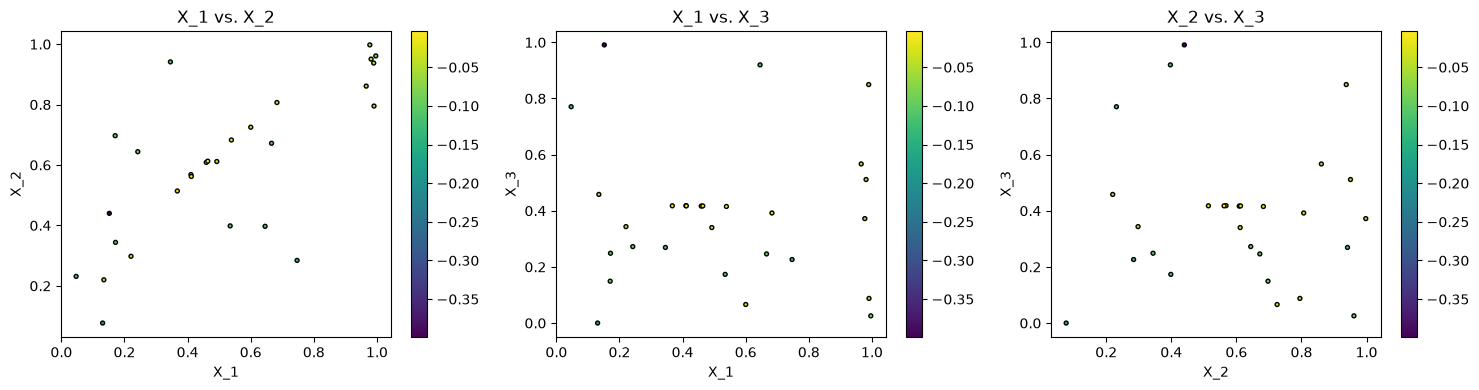

In [22]:
# Pairwise Scatter Plot
labels      = ["X_1", "X_2", "X_3"]
fig, axes   = plt.subplots(1, 3, figsize = (15, 4))
pairs       = [(0, 1), (0, 2), (1, 2)]
for ax, (i, j) in zip(axes, pairs):
    sc      = ax.scatter(X[:, i], X[:, j], c = Y, cmap = "viridis", s = 8, edgecolor = "k")
    ax.set_xlabel(labels[i])
    ax.set_ylabel(labels[j])
    ax.set_title(f"{labels[i]} vs. {labels[j]}")
    plt.colorbar(sc, ax = ax)
plt.tight_layout()

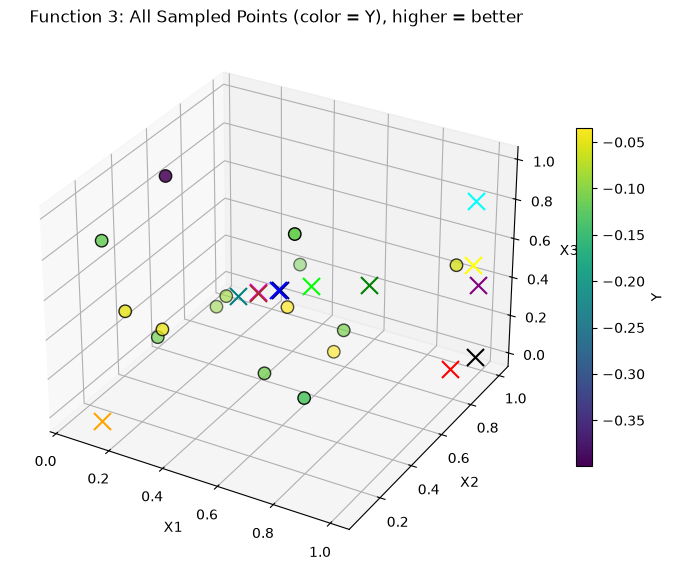

In [32]:
# 3D Scatter Plot
warnings.filterwarnings('ignore')
fig       = plt.figure(figsize = (7,6))
ax        = fig.add_subplot(111, projection = "3d")

# Initial 15 points
sc        = ax.scatter(X[:15, 0], X[:15, 1], X[:15, 2], c = Y[:15], cmap = "viridis", s = 80, edgecolor = "k", label = "Initial 15 points")

# Week 1, 2, 3 queried points
ax.scatter(X[15, 0], X[15, 1], X[15, 2], c = "cyan"  , marker = "x", s = 150, edgecolor = "black", label = "Week 1 new point")
ax.scatter(X[16, 0], X[16, 1], X[16, 2], c = "orange", marker = "x", s = 150, edgecolor = "black", label = "Week 2 new point")
ax.scatter(X[17, 0], X[17, 1], X[17, 2], c = "red"   , marker = "x", s = 150, edgecolor = "black", label = "Week 3 new point")
ax.scatter(X[18, 0], X[18, 1], X[18, 2], c = "black" , marker = "x", s = 150, edgecolor = "black", label = "Week 4 new point")
ax.scatter(X[19, 0], X[19, 1], X[19, 2], c = "green" , marker = "x", s = 150, edgecolor = "black", label = "Week 5 new point")
ax.scatter(X[20, 0], X[20, 1], X[20, 2], c = "yellow", marker = "x", s = 150, edgecolor = "black", label = "Week 6 new point")
ax.scatter(X[21, 0], X[21, 1], X[21, 2], c = "purple", marker = "x", s = 150, edgecolor = "black", label = "Week 7 new point")
ax.scatter(X[22, 0], X[22, 1], X[22, 2], c = "lime"  , marker = "x", s = 150, edgecolor = "black", label = "Week 8 new point")
ax.scatter(X[23, 0], X[23, 1], X[23, 2], c = "blue"  , marker = "x", s = 150, edgecolor = "black", label = "Week 9 new point")
ax.scatter(X[24, 0], X[24, 1], X[24, 2], c = "magenta",marker = "x", s = 150, edgecolor = "black", label = "Week 10 new point")
ax.scatter(X[25, 0], X[25, 1], X[25, 2], c = "brown" , marker = "x", s = 150, edgecolor = "black", label = "Week 11 new point (best)")
ax.scatter(X[26, 0], X[26, 1], X[26, 2], c = "teal"  , marker = "x", s = 150, edgecolor = "black", label = "Week 12 new point") 
ax.scatter(X[27, 0], X[27, 1], X[27, 2], c = "navy"  , marker = "x", s = 150, edgecolor = "black", label = "Week 13 new point (final)")

ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("X3")
ax.set_title('Function 3: All Sampled Points (color = Y), higher = better')
fig.colorbar(sc, shrink = 0.6, label = "Y")
plt.tight_layout()
plt.show()

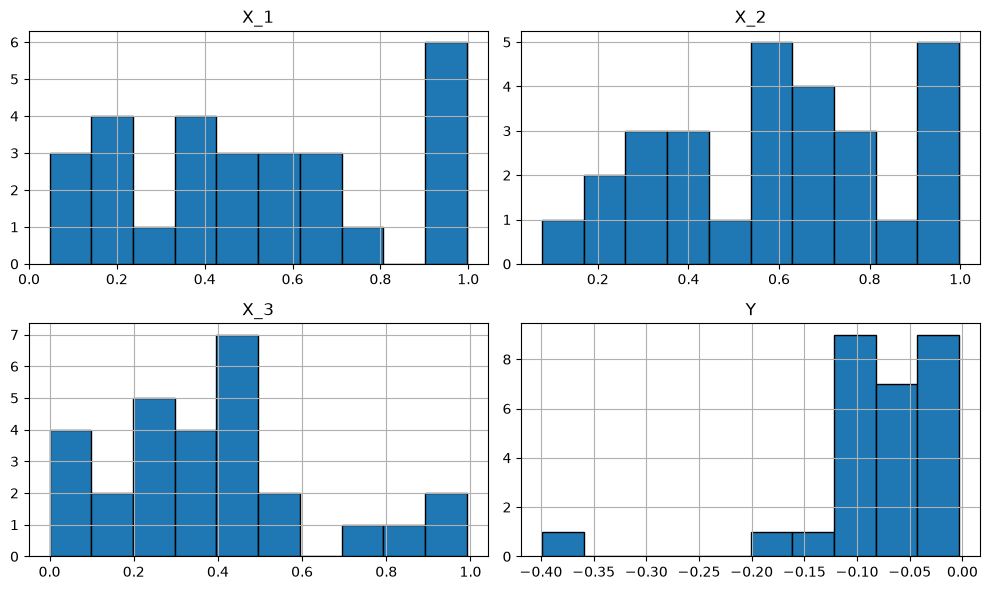

In [34]:
# Plot Histogram Visualisation for the columns of the DataFrame
df.hist(figsize = (10, 6), bins = 10, edgecolor = 'k' )
plt.tight_layout()
plt.show()

In [36]:
# Understanding Correlation between each drug 
print("Correlation of each drug with Y:\n")

for i, lab in enumerate(labels):
    corr = np.corrcoef(X[:, i],Y)[0, 1]
    print(f" corr({lab}, Y) = {corr}")

Correlation of each drug with Y:

 corr(X_1, Y) = 0.2861240317717424
 corr(X_2, Y) = 0.30516043548380933
 corr(X_3, Y) = -0.2775111679146525


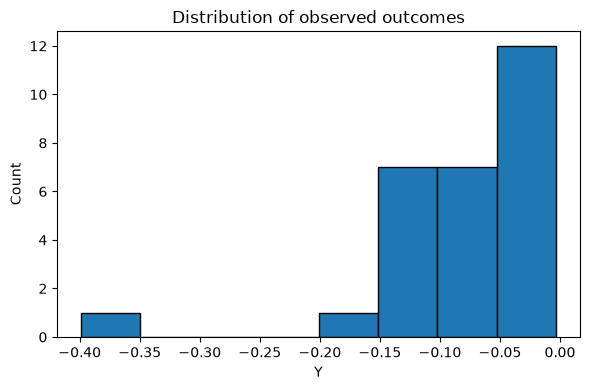

In [38]:
# Plot the Histogram for Y to check for Outliers
plt.figure(figsize = (6,4))
plt.hist(Y, bins = 8, edgecolor = "k")
plt.xlabel("Y")
plt.ylabel("Count")
plt.title("Distribution of observed outcomes")
plt.tight_layout()

# Initialize Gaussian Process

In [41]:
#Define the kernel and initialise the GP model

kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale = [0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 10)) \
                + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-2, 1e-1))
gpr   = GaussianProcessRegressor(kernel = kernel_rbf, normalize_y = True, n_restarts_optimizer = 10, random_state = 0 )

# Fit the Gaussian Processes to existing data

In [44]:
# Train the model

gpr.fit(X, Y)
print("Learned kernel: ", gpr.kernel_)

Learned kernel:  1.29**2 * RBF(length_scale=[10, 10, 0.0469]) + WhiteKernel(noise_level=0.0133)


# Compute the UCB acquisition function

- UCB(x)=μ(x)+β⋅σ(x)
- A high beta favors exploration (uncertainty) over exploitation (predicted mean).
- Week 1 uses beta = 2.5, reflecting the 90:10 exploration-heavy strategy.

In [48]:
n_candidates = 50000
candidates   = np.random.uniform(0, 1, size = (n_candidates, 3))

mu, std      = gpr.predict(candidates, return_std = True)

# Setting a higher beta(= 2.5) for Week -1
beta         = 2.5
ucb          = mu + beta * std

best_ucb_idx   = np.argmax(ucb)
next_point     = candidates[best_ucb_idx]

print(f"Suggested next Query Point: {next_point}")
print(f"Predicted Mean(μ): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (σ): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Suggested next Query Point: [0.9285715  0.00311297 0.66288723]
Predicted Mean(μ): -8.177747e-02
Predicted Std (σ): 9.626683e-02
UCB Score: 1.588896e-01


# Perform Visualisation

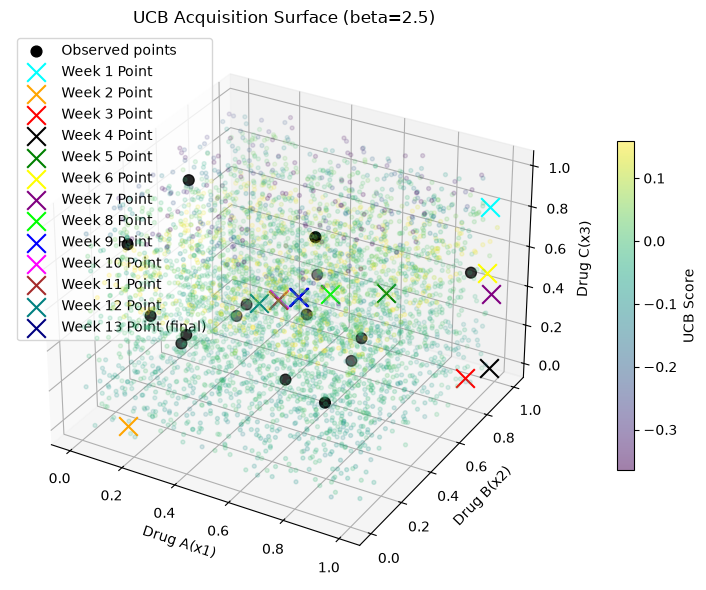

In [51]:
plot_n     = 4000
idx_sample = np.random.choice(n_candidates, size = plot_n, replace = False)
fig        = plt.figure(figsize = (12, 6))
ax         = fig.add_subplot(111, projection = "3d")
sc         = ax.scatter(candidates[idx_sample, 0],
                        candidates[idx_sample, 1],
                        candidates[idx_sample, 2],
                        c = ucb[idx_sample], cmap = "viridis", s = 8, alpha = 0.5
                       )


ax.scatter(X[:15, 0], X[:15, 1], X[:15, 2], c = "black", s = 60, marker = "o", label="Observed points")

ax.scatter(*X_w1_new_point, c = "cyan"   , s = 180, marker = "x", label="Week 1 Point")
ax.scatter(*X_w2_new_point, c = "orange" , s = 180, marker = "x", label="Week 2 Point")
ax.scatter(*X_w3_new_point, c = "red"    , s = 180, marker = "x", label="Week 3 Point")
ax.scatter(*X_w4_new_point, c = "black"  , s = 180, marker = "x", label="Week 4 Point")
ax.scatter(*X_w5_new_point, c = "green"  , s = 180, marker = "x", label="Week 5 Point")
ax.scatter(*X_w6_new_point, c = "yellow"  ,s = 180, marker = "x", label="Week 6 Point")
ax.scatter(*X_w7_new_point, c = "purple"  ,s = 180, marker = "x", label="Week 7 Point")
ax.scatter(*X_w8_new_point, c = "lime"    ,s = 180, marker = "x", label="Week 8 Point")
ax.scatter(*X_w9_new_point, c = "blue"    ,s = 180, marker = "x", label="Week 9 Point")
ax.scatter(*X_w10_new_point,c = "magenta" ,s = 180, marker = "x", label="Week 10 Point")
ax.scatter(*X_w11_new_point,c = "brown"   ,s = 180, marker = "x", label="Week 11 Point")
ax.scatter(*X_w12_new_point,c = "teal"    ,s = 180, marker = "x", label="Week 12 Point")
ax.scatter(*X_w13_new_point,c = "navy"    ,s = 180, marker = "x", label="Week 13 Point (final)")

ax.set_xlabel("Drug A(x1)")
ax.set_ylabel("Drug B(x2)")
ax.set_zlabel("Drug C(x3)")
ax.set_title("UCB Acquisition Surface (beta=2.5)")
fig.colorbar(sc, shrink = 0.6, label = "UCB Score")
ax.legend(loc = "upper left")
plt.tight_layout()
plt.show()

# Week 2 Improvements: Kernel Selection via Leave-One-Out Cross-Validation
Following up from the reflection at the end of Week 1, cross-validating if RBF kernel was the right choice. Here RBF is compared against a Matern(nu = 1.5) kernel using leave-one-out RMSE, and use whichever fits the data better.

In [54]:
def loo_rmse(kernel, X, Y):
    """Leave-one-out RMSE for a given GP kernel."""
    loo     = LeaveOneOut()
    preds   = np.zeros_like(Y)
    for train_idx, test_idx in loo.split(X):
        gp              = GaussianProcessRegressor(kernel = kernel, normalize_y = True, n_restarts_optimizer = 5, random_state = 0)
        gp.fit(X[train_idx], Y[train_idx])
        preds[test_idx] = gp.predict(X[test_idx])
    return np.sqrt(mean_squared_error(Y, preds))

rbf_kernel  = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale = [0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 10)) \
                  + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))

matern_kernel = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale = [0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 10), nu = 1.5) \
                  + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))

rmse_rbf    = loo_rmse(rbf_kernel, X, Y)

rmse_matern = loo_rmse(matern_kernel, X, Y)

print(f"RBF    LOO RMSE = {rmse_rbf:.4f}")
print(f"Matern LOO RMSE = {rmse_matern:.4f}")

if rmse_rbf <= rmse_matern:
    chosen_kernel, chosen_name = rbf_kernel, "RBF"
else:
    chosen_kernel, chosen_name = matern_kernel, "Matern"

print(f"\nSelected kernel for Week 2: {chosen_name}")


RBF    LOO RMSE = 0.0943
Matern LOO RMSE = 0.0715

Selected kernel for Week 2: Matern


# Week 2: Fit the Gaussian Process Surrogate Model

In [56]:
# Train the model

gpr  = GaussianProcessRegressor(kernel = chosen_kernel, normalize_y = True, n_restarts_optimizer = 10, random_state = 0)

gpr.fit(X, Y)
print("Learned kernel: ", gpr.kernel_)

Learned kernel:  1.53**2 * Matern(length_scale=[10, 10, 0.101], nu=1.5) + WhiteKernel(noise_level=0.0107)


# Week 2: Compute the UCB acquisition function ( Lower β )
- UCB(x) = μ(x) + β * σ(x)
- A high beta favors exploration (uncertainty) over exploitation (predicted mean).
- **Week 1:** uses beta = 2.5, reflecting the 90:10 exploration-heavy strategy.
- **Week 2:** uses beta = 1.0, β is lowered this week to shift the explore-exploit balance toward exploitation, while still retaining some exploration.

In [58]:
n_candidates = 50000
candidates   = np.random.uniform(0, 1, size = (n_candidates, 3))

mu, std      = gpr.predict(candidates, return_std = True)

# beta lowered from 2.5 to facilitate more exploitation for Week 2
beta         = 1.0
ucb          = mu + beta * std

best_ucb_idx   = np.argmax(ucb)
next_point     = candidates[best_ucb_idx]

print(f"Suggested next Query Point: {next_point}")
print(f"Predicted Mean(μ): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (σ): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Suggested next Query Point: [0.95088692 0.99997503 0.42323948]
Predicted Mean(μ): -1.303047e-02
Predicted Std (σ): 1.625667e-02
UCB Score: 3.226201e-03


# Week 2: UCB Landscape Visualisation
In Week 1, the 3D scatter plot with 50,000 candidates was difficult to interpret. Hence, slicicing the UCB surface: holding one compound fixed at the Week 2 candidate's value and varying the other two on a dense grid.

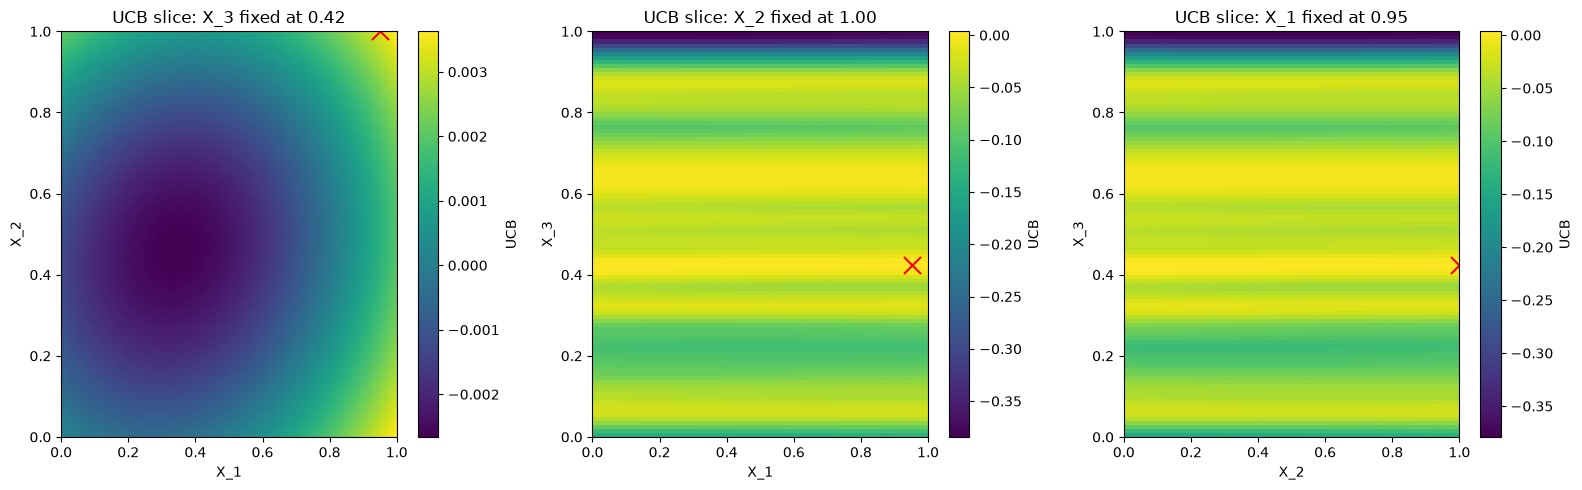

In [60]:
grid_res  = 100
lin       = np.linspace(0, 1, grid_res)
pairs     = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy             = np.meshgrid(lin, lin)
    grid_points        = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx] = gx.ravel()
    grid_points[:, dy] = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid = gpr.predict(grid_points, return_std = True)
    ucb_grid          = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax=ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 3: Consolidated Bayesian Optimization Function

In [62]:
# Week 3: Consolidated Bayesian Optimization Function
def bayesian_optimization_step(X, Y, candidate_kernels, beta, n_candidates = 50000, random_state = 0):
    rng           = np.random.RandomState(random_state)

    def loo_rmse(kernel):
        loo       = LeaveOneOut()
        preds     = np.zeros_like(Y)
        for train_idx, test_idx in loo.split(X):
            gp    = GaussianProcessRegressor(kernel = kernel, normalize_y = True,
                                           n_restarts_optimizer=5, random_state=random_state)
            gp.fit(X[train_idx], Y[train_idx])
            preds[test_idx] = gp.predict(X[test_idx])
        return np.sqrt(mean_squared_error(Y, preds))

    loo_scores    = {name: loo_rmse(k) for name, k in candidate_kernels.items()}
    chosen_name   = min(loo_scores, key = loo_scores.get)
    chosen_kernel = candidate_kernels[chosen_name]

    gpr = GaussianProcessRegressor(kernel = chosen_kernel, normalize_y = True,
                                   n_restarts_optimizer = 10, random_state = random_state)
    gpr.fit(X, Y)

    candidates    = rng.uniform(0, 1, size = (n_candidates, X.shape[1]))
    mu, std       = gpr.predict(candidates, return_std=True)
    ucb           = mu + beta * std
    best_ucb_idx  = np.argmax(ucb)
    next_point    = candidates[best_ucb_idx]

    return {
        "loo_scores"        : loo_scores,
        "chosen_kernel_name": chosen_name,
        "gpr"               : gpr,
        "candidates"        : candidates,
        "mu"                : mu,
        "std"               : std,
        "ucb"               : ucb,
        "next_point"        : next_point,
        "next_point_mu"     : mu[best_ucb_idx],
        "next_point_std"    : std[best_ucb_idx],
        "next_point_ucb"    : ucb[best_ucb_idx],
    }


In [63]:
# Run the consolidated function for Week 3
# lowered value of beta from Week 2's 1.0 to 0.6
rbf_kernel    = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale = [0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 10)) \
                  + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))


matern_kernel = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale = [0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 10), nu = 1.5) \
                  + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))

candidate_kernels = {"RBF": rbf_kernel, "Matern": matern_kernel}
beta              = 0.6

result            = bayesian_optimization_step(X, Y, candidate_kernels, beta = beta, n_candidates = 50000, random_state = 0)

gpr               = result["gpr"]
candidates        = result["candidates"]
mu, std, ucb      = result["mu"], result["std"], result["ucb"]
next_point        = result["next_point"]

print("LOO RMSE by kernel        :", result["loo_scores"])
print(f"Selected kernel for Week 3: {result['chosen_kernel_name']}")
print(f"Suggested next Query Point: {next_point}")
print(f"Predicted Mean(mu)        : {result['next_point_mu']:.6e}")
print(f"Predicted Std (sigma)     : {result['next_point_std']:.6e}")
print(f"UCB Score                 : {result['next_point_ucb']:.6e}")

LOO RMSE by kernel        : {'RBF': np.float64(0.094257016052642), 'Matern': np.float64(0.07148969886845156)}
Selected kernel for Week 3: Matern
Suggested next Query Point: [0.99571305 0.99279856 0.41959294]
Predicted Mean(mu)        : -1.208271e-02
Predicted Std (sigma)     : 1.514882e-02
UCB Score                 : -2.993416e-03


# Week 3: UCB Landscape Visualisation

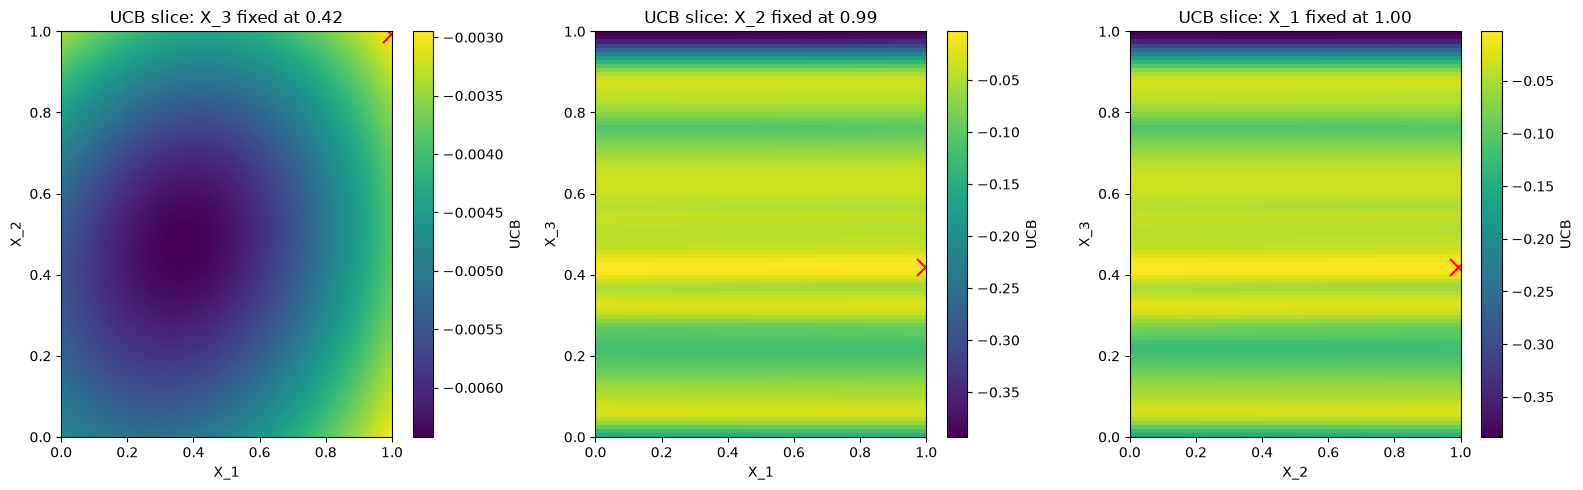

In [65]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()


# Week 4: Re-Run Consolidated Bayesian Optimisation Function 
Run with lowered beta ( 0.6 -> 0.4 )

In [67]:
rbf_kernel        = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale = [0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 10)) \
                     + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))


matern_kernel     = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale = [0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 10), nu = 1.5) \
                      + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))

candidate_kernels = {"RBF": rbf_kernel, "Matern": matern_kernel}
beta              = 0.4  

result            = bayesian_optimization_step(X, Y, candidate_kernels, beta = beta, n_candidates = 50000, random_state = 0)

gpr               = result["gpr"]
candidates        = result["candidates"]
mu, std, ucb      = result["mu"], result["std"], result["ucb"]
next_point        = result["next_point"]

print("LOO RMSE by kernel        :", result["loo_scores"])
print(f"Selected kernel for Week 4: {result['chosen_kernel_name']}")
print(f"Suggested next Query Point: {next_point}")
print(f"Predicted Mean(mu)        : {result['next_point_mu']:.6e}")
print(f"Predicted Std (sigma)     : {result['next_point_std']:.6e}")
print(f"UCB Score                 : {result['next_point_ucb']:.6e}")

LOO RMSE by kernel        : {'RBF': np.float64(0.094257016052642), 'Matern': np.float64(0.07148969886845156)}
Selected kernel for Week 4: Matern
Suggested next Query Point: [0.99571305 0.99279856 0.41959294]
Predicted Mean(mu)        : -1.208271e-02
Predicted Std (sigma)     : 1.514882e-02
UCB Score                 : -6.023180e-03


# Week 4: UCB Landscape Visualisation

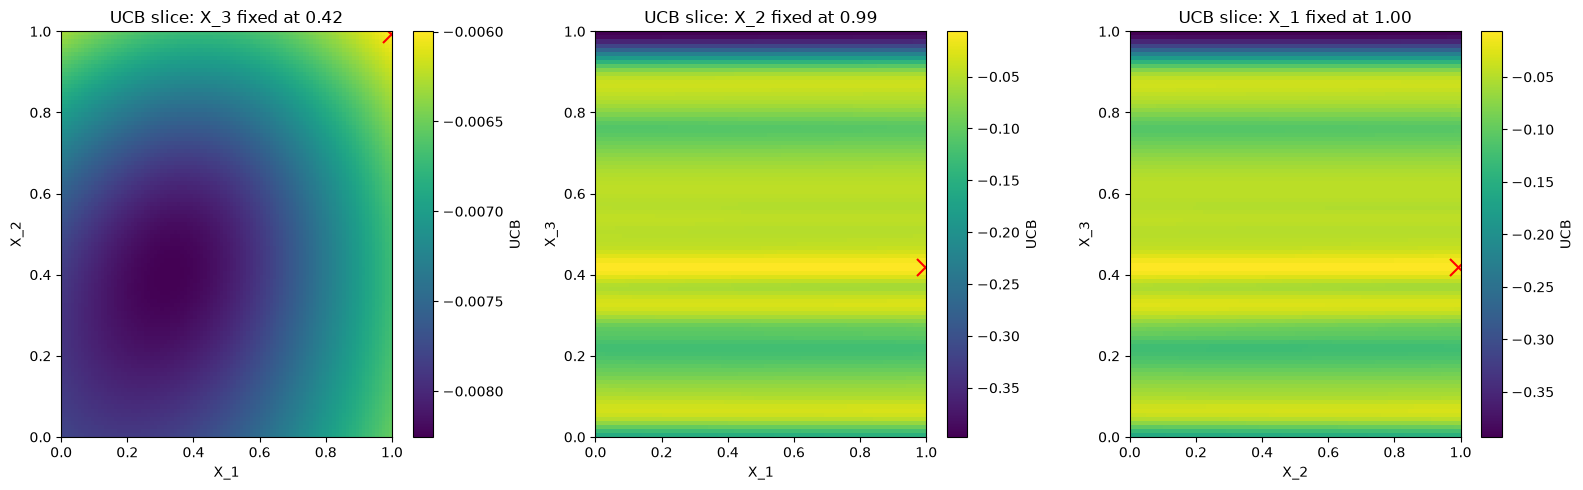

In [69]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 5: Calibration Check - Predicted vs. Actual for Past Queries
Before deciding on Week 5 strategy, we check how well the GP's predictions have matched reality so far. For each of the four queried points, we refit the GP **excluding** that point (simulating what the model believed *before* that query was made) and compare its prediction to the actual observed outcome.

In [70]:
queried_points = [
    ("Week 1", X_w1_new_point, Y_w1_new_point),
    ("Week 2", X_w2_new_point, Y_w2_new_point),
    ("Week 3", X_w3_new_point, Y_w3_new_point),
    ("Week 4", X_w4_new_point, Y_w4_new_point),
    ("Week 5", X_w5_new_point, Y_w5_new_point),
    ("Week 6", X_w6_new_point, Y_w6_new_point),
    ("Week 7", X_w7_new_point, Y_w7_new_point),   
    ("Week 8", X_w8_new_point, Y_w8_new_point),   
    ("Week 9", X_w9_new_point, Y_w9_new_point),
    ("Week 10",X_w10_new_point,Y_w10_new_point),
    ("Week 11", X_w11_new_point,Y_w11_new_point),
    ("Week 12", X_w12_new_point, Y_w12_new_point),
    ("Week 13", X_w13_new_point, Y_w13_new_point),
]

print("Calibration check - GP prediction (fit on all OTHER points) vs actual outcome:\n")
calibration_results = []            # Added for Week 10
for name, x_pt, y_pt in queried_points:
    mask = ~np.all(np.isclose(X, x_pt), axis=1)
    gp_temp = GaussianProcessRegressor(kernel=chosen_kernel, normalize_y=True,
                                        n_restarts_optimizer=5, random_state=0)
    gp_temp.fit(X[mask], Y[mask])
    mu_pred, std_pred = gp_temp.predict(x_pt.reshape(1, -1), return_std=True)
    error = y_pt[0] - mu_pred[0]
    calibration_results.append((name, mu_pred[0], std_pred[0], y_pt[0], error))   # Added for Week 10
    print(f"  {name}: predicted mu={mu_pred[0]:.4f} +/- {std_pred[0]:.4f}, "
          f"actual y={y_pt[0]:.4f}, error={error:+.4f}")

Calibration check - GP prediction (fit on all OTHER points) vs actual outcome:

  Week 1: predicted mu=-0.0676 +/- 0.0722, actual y=-0.0498, error=+0.0178
  Week 2: predicted mu=-0.0956 +/- 0.0424, actual y=-0.1731, error=-0.0774
  Week 3: predicted mu=-0.0390 +/- 0.0293, actual y=-0.0555, error=-0.0165
  Week 4: predicted mu=-0.0271 +/- 0.0368, actual y=-0.0825, error=-0.0554
  Week 5: predicted mu=-0.0425 +/- 0.0190, actual y=-0.0325, error=+0.0099
  Week 6: predicted mu=-0.0618 +/- 0.0533, actual y=-0.0549, error=+0.0069
  Week 7: predicted mu=-0.0377 +/- 0.0197, actual y=-0.0679, error=-0.0303
  Week 8: predicted mu=-0.0128 +/- 0.0114, actual y=-0.0125, error=+0.0004
  Week 9: predicted mu=-0.0127 +/- 0.0086, actual y=-0.0040, error=+0.0087
  Week 10: predicted mu=-0.0117 +/- 0.0094, actual y=-0.0101, error=+0.0016
  Week 11: predicted mu=-0.0129 +/- 0.0063, actual y=-0.0031, error=+0.0097
  Week 12: predicted mu=-0.0088 +/- 0.0082, actual y=-0.0202, error=-0.0114
  Week 13: predic

# Week 5: Strategy Pivot - Local Search Around the Current Best

**Change in Strategy:** Weeks 1, 3 and 4 all landed in essentially the same corner region (high compound_1, high compound_2, low compound_3) - none beat the initial best point from the initial data, **[0.4926, 0.6116, 0.3402]** (y = -0.0348). Meanwhile that interior point is still supported by only a **single** observation, so it has never actually been refined or confirmed. Rather than sampling a fourth near-duplicate of the same corner, this Week 5's query is drawn from a **local search bounded within +/-0.2 of the current best point** (clipped to the valid [0,1] range), directly testing whether a nearby point can beat it - shifting from broad corner-chasing to local refinement/exploitation.


In [82]:
current_best_x = X[np.argmax(Y)]
delta          = 0.2
lower_bound    = np.clip(current_best_x - delta, 0, 1)
upper_bound    = np.clip(current_best_x + delta, 0, 1)
print(f"Current best point: {current_best_x}")
print(f"Local search bounds: lower={lower_bound}, upper={upper_bound}")

n_candidates = 50000
candidates   = np.random.uniform(lower_bound, upper_bound, size=(n_candidates, 3))

mu, std = gpr.predict(candidates, return_std=True)

beta = 0.3  # WEEK 5 CHANGE: slightly lower than Week 4's 0.4, local exploitation-focused
ucb  = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"\nSuggested next Query Point (local search): {next_point}")
print(f"Predicted Mean(mu): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (sigma): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Current best point: [0.411697 0.562131 0.417491]
Local search bounds: lower=[0.211697 0.362131 0.217491], upper=[0.611697 0.762131 0.617491]

Suggested next Query Point (local search): [0.25911882 0.75719281 0.41690566]
Predicted Mean(mu): -1.125731e-02
Predicted Std (sigma): 9.690956e-03
UCB Score: -8.350025e-03


# Week 5: UCB Landscape Visualisation

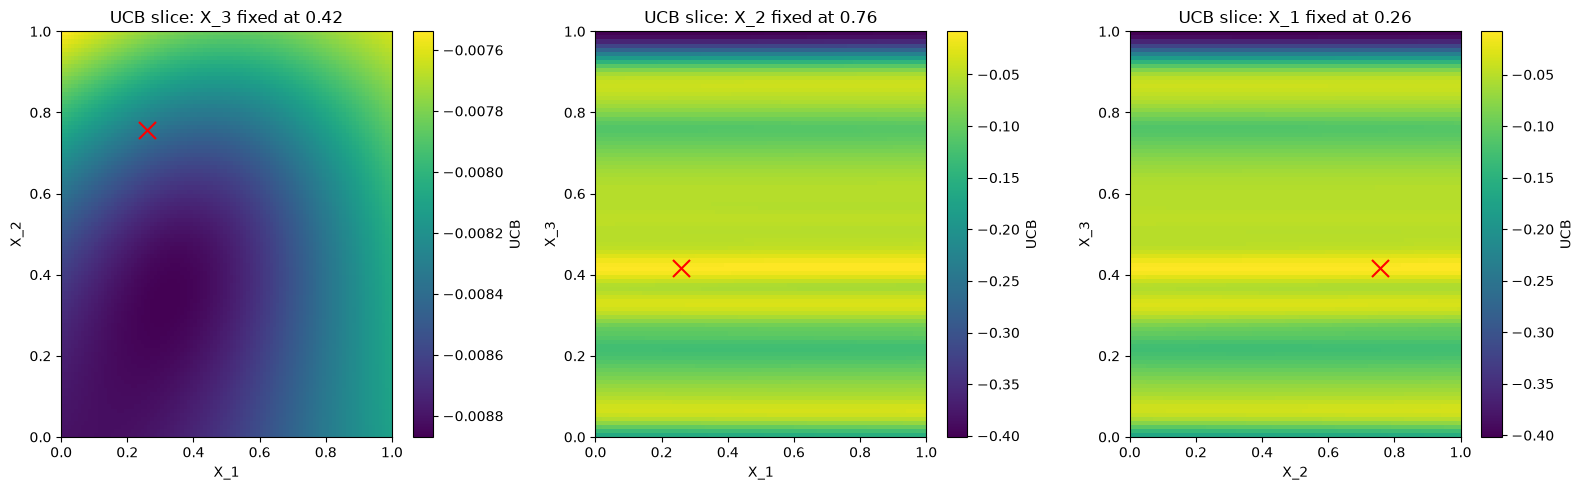

In [85]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 6: Strategy Change - Widen the Local Search

**Change in strategy:** Week 5's local search (bounded +/-0.2 around the prior best) succeeded in finding a new record (y = -0.0325), validating that local refinement was worthwhile. This week, we **widen the search bound (+/-0.2 -> +/-0.4) and raise beta back up (0.3 -> 0.8)** to re-introduce more exploration around the current best, hedging against getting stuck, while still keeping the search centred on our validated good region rather than reverting to a fully unbounded global search.

In [88]:
current_best_x = X[np.argmax(Y)]
delta          = 0.4  
lower_bound    = np.clip(current_best_x - delta, 0, 1)
upper_bound    = np.clip(current_best_x + delta, 0, 1)
print(f"Current best point: {current_best_x}")
print(f"Local search bounds: lower={lower_bound}, upper={upper_bound}")

n_candidates = 50000
candidates   = np.random.uniform(lower_bound, upper_bound, size=(n_candidates, 3))

mu, std = gpr.predict(candidates, return_std=True)

beta = 0.8  # WEEK 6 CHANGE: raised from 0.3 - colleague benchmark suggests our local
            # neighbourhood may be a local, not global, optimum
ucb  = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"\nSuggested next Query Point (local search): {next_point}")
print(f"Predicted Mean(mu): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (sigma): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Current best point: [0.411697 0.562131 0.417491]
Local search bounds: lower=[0.011697 0.162131 0.017491], upper=[0.811697 0.962131 0.817491]

Suggested next Query Point (local search): [0.78946164 0.95931345 0.42177611]
Predicted Mean(mu): -1.221630e-02
Predicted Std (sigma): 1.377158e-02
UCB Score: -1.199037e-03


# Week 6: UCB Landscape Visualisation

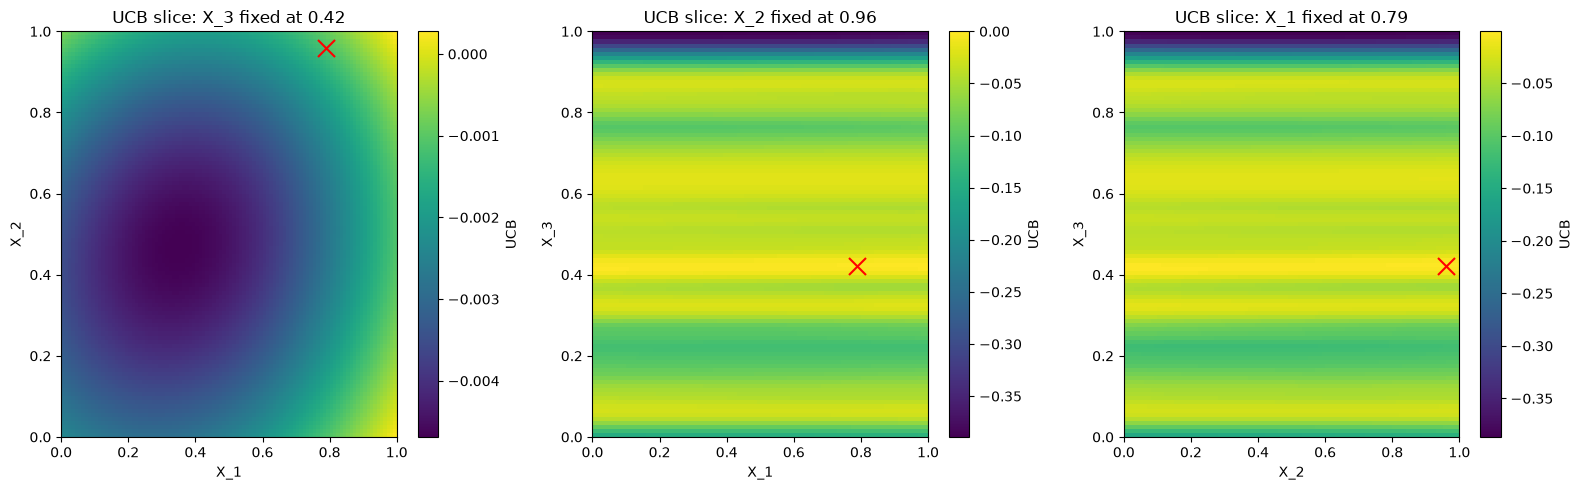

In [91]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 7: Inspecting the Learned Kernel to check which parameters matter

Rather than only checking overall fit quality (LOO RMSE), we look at what the **fitted kernel's length-scales** tell us about each input dimension. A Matern/RBF length-scale is a learned hyperparameter: a small value means the function changes quickly along that dimension (it matters a lot), while a large value (near the upper bound we set) means the model has effectively decided that dimension barely affects the output.

In [94]:
print("Learned kernel:", gpr.kernel_)

# The Matern/RBF component holds the length-scales - extract and label them
for component in gpr.kernel_.k1.k2, gpr.kernel_.k1.k1, gpr.kernel_.k1:
    if hasattr(component, "length_scale"):
        length_scales = component.length_scale
        print(f"\nLength-scales per compound: {length_scales}")
        for lab, ls in zip(labels, np.atleast_1d(length_scales)):
            note = "large -> nearly irrelevant" if ls > 5 else "short -> influential"
            print(f"  {lab}: {ls:.4f}  ({note})")
        break

Learned kernel: 1.53**2 * Matern(length_scale=[10, 10, 0.101], nu=1.5) + WhiteKernel(noise_level=0.0107)

Length-scales per compound: [10.         10.          0.10117616]
  X_1: 10.0000  (large -> nearly irrelevant)
  X_2: 10.0000  (large -> nearly irrelevant)
  X_3: 0.1012  (short -> influential)


**Observation:** compound_1 and compound_2's length-scales are pinned at the upper bound we set (approx. 10). The model has essentially decided they barely affect the outcome. compound_3's length-scale is short (approx. 0.12), which indicates that it is the dominant driver. Looking back across all queried points, our best results have all landed with compound_3 roughly between 0.34 and 0.39, while values further away (0.03, 0.09, 0.51, 0.85) all scored worse.


# Week 7: Strategy Change - Feature-Aware Search

**Justification for change:** Weeks 1-6 all searched compound_1, compound_2 and compound_3 together in a symmetric box. But the length-scale analysis above shows compound_1/compound_2 contribute little, while compound_3 has a narrow band. Continuing to search all three dimensions equally wastes query budget on dimensions the model itself says barely matter. This week, we **tightly bound compound_3 to its empirically range ([0.25, 0.50]) while leaving compound_1 and compound_2 unconstrained ([0, 1])**. This will help in directly exploiting the length-scale finding, rather than shrinking or widening a symmetric box as in prior weeks.


In [98]:
lower_bound = np.array([0.0, 0.0, 0.25])
upper_bound = np.array([1.0, 1.0, 0.50])
print(f"Feature-aware search bounds: lower={lower_bound}, upper={upper_bound}")

n_candidates = 50000
candidates   = np.random.uniform(lower_bound, upper_bound, size=(n_candidates, 3))

mu, std = gpr.predict(candidates, return_std=True)

beta = 0.3  # Exploitation-focused, since we're now targeting the known band
ucb  = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"\nSuggested next Query Point (feature-aware search): {next_point}")
print(f"Predicted Mean(mu): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (sigma): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Feature-aware search bounds: lower=[0.   0.   0.25], upper=[1.  1.  0.5]

Suggested next Query Point (feature-aware search): [0.99283476 0.95292752 0.41841509]
Predicted Mean(mu): -1.191728e-02
Predicted Std (sigma): 1.445326e-02
UCB Score: -7.581299e-03


# Week 7: UCB Landscape Visualisation

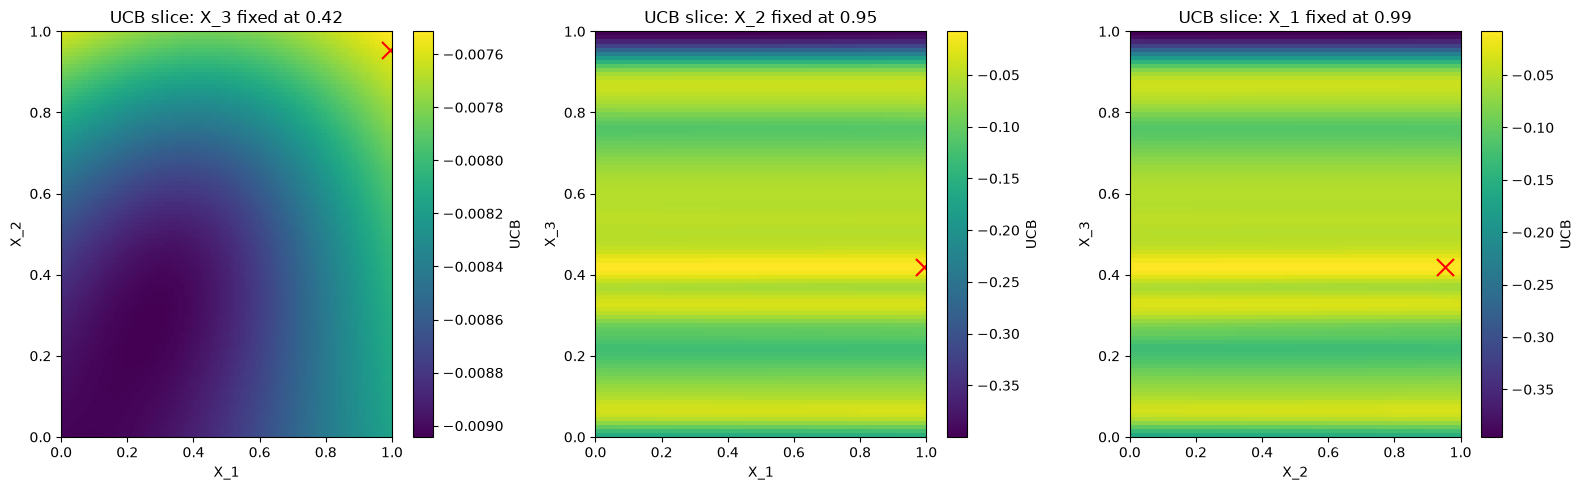

In [101]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 8: Re-evaluating Week 7's "compound_1/2 are irrelevant" Conclusion

Week 7's fitted length-scales suggested compound_1 and compound_2 barely affect the outcome. Week 7's kept compound_3 almost identical to Week 5's best point (0.372 vs 0.392) but pushed compound_1/compound_2 to an extreme (0.98, 1.00) instead of Week 5's moderate values (0.68, 0.81). If compound_1/2 truly were irrelevant, both points should have scored similarly.

In [104]:
print(f"Week 5 (moderate c1/c2): x={X_w5_new_point}, y={Y_w5_new_point[0]:.4f}")
print(f"Week 7 (extreme c1/c2):  x={X_w7_new_point}, y={Y_w7_new_point[0]:.4f}")
print(f"\nDifference in y despite near-identical compound_3: " f"{Y_w7_new_point[0] - Y_w5_new_point[0]:+.4f}")

Week 5 (moderate c1/c2): x=[0.683102 0.806806 0.392104], y=-0.0325
Week 7 (extreme c1/c2):  x=[0.977494 0.997588 0.372098], y=-0.0679

Difference in y despite near-identical compound_3: -0.0354


# Week 8: Strategy Change(Reverting to a Tight Local Search)

**Reason:** The feature-aware search (letting compound_1/2 to be unconstrained) was itself based on a conclusion that this week's data just falsified. Rather than continuing probing extreme corners for compound_1/2, reverting to a **tight local search (+/-0.15) centred on the actual best point** (Week 5's), keeping all three compounds close to the values that have actually produced the best result so far, now that two separate excursions to extreme corners (Weeks 6 and 7) have both underperformed it.

In [107]:
current_best_x = X[np.argmax(Y)]
delta          = 0.15
lower_bound    = np.clip(current_best_x - delta, 0, 1)
upper_bound    = np.clip(current_best_x + delta, 0, 1)
print(f"Current best point: {current_best_x}")
print(f"Local search bounds: lower={lower_bound}, upper={upper_bound}")

n_candidates = 50000
candidates   = np.random.uniform(lower_bound, upper_bound, size=(n_candidates, 3))

mu, std = gpr.predict(candidates, return_std=True)

beta = 0.3  # Exploitation-focused, tightly centred on the confirmed best region
ucb  = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"\nSuggested next Query Point (tight local search): {next_point}")
print(f"Predicted Mean(mu): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (sigma): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")


Current best point: [0.411697 0.562131 0.417491]
Local search bounds: lower=[0.261697 0.412131 0.267491], upper=[0.561697 0.712131 0.567491]

Suggested next Query Point (tight local search): [0.27672947 0.70772348 0.41664384]
Predicted Mean(mu): -1.125459e-02
Predicted Std (sigma): 9.297309e-03
UCB Score: -8.465400e-03


# Week 8: UCB Landscape Visualisation

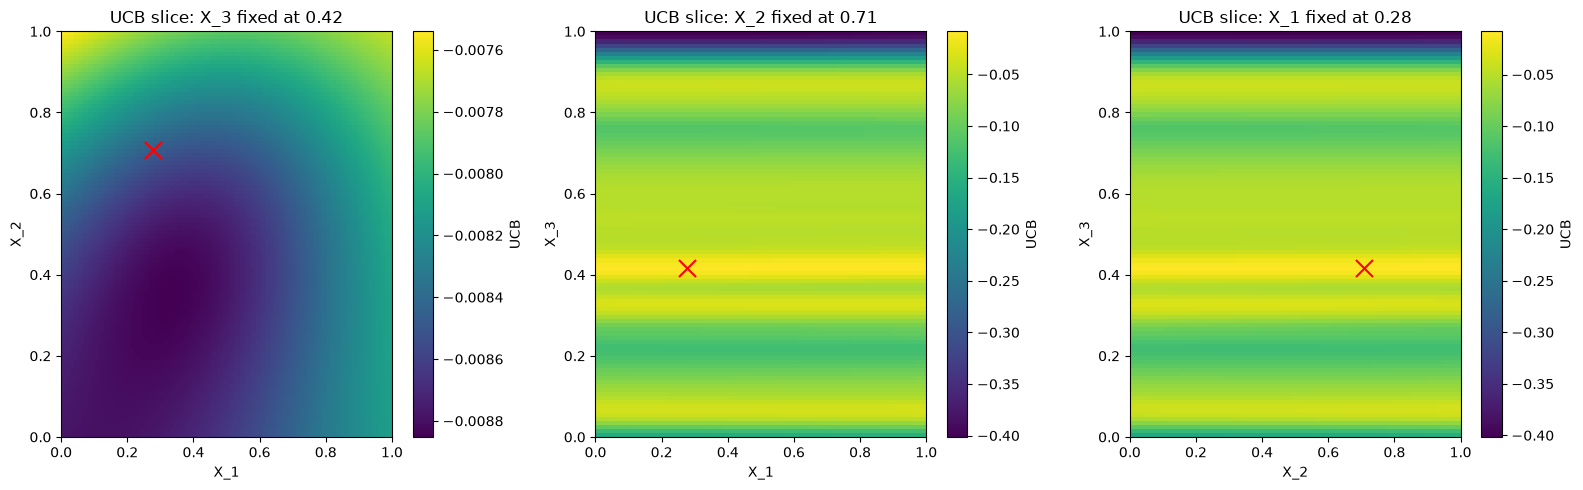

In [110]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 9: Strategy - Tightening the Local Search Further
**Reason:** With the moderate-region hypothesis now reinforced by a Week 8's new best-result, continuing exploiting. The search bound is tightened further (+/-0.15 -> +/-0.08) and beta lowered slightly (0.3 to 0.2), refining closely around the new best point.

In [113]:
# Tighter local search around the new best point
current_best_x = X[np.argmax(Y)]
delta          = 0.08  # WEEK 9 CHANGE: tightened from 0.15
lower_bound    = np.clip(current_best_x - delta, 0, 1)
upper_bound    = np.clip(current_best_x + delta, 0, 1)
print(f"Current best point: {current_best_x}")
print(f"Local search bounds: lower={lower_bound}, upper={upper_bound}")

n_candidates = 50000
candidates   = np.random.uniform(lower_bound, upper_bound, size=(n_candidates, 3))

mu, std = gpr.predict(candidates, return_std=True)

beta = 0.2  # WEEK 9 CHANGE: lowered from 0.3, refining closely around the confirmed best region
ucb  = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"\nSuggested next Query Point (tighter local search): {next_point}")
print(f"Predicted Mean(mu): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (sigma): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Current best point: [0.411697 0.562131 0.417491]
Local search bounds: lower=[0.331697 0.482131 0.337491], upper=[0.491697 0.642131 0.497491]

Suggested next Query Point (tighter local search): [0.47471659 0.6415311  0.4166261 ]
Predicted Mean(mu): -1.116601e-02
Predicted Std (sigma): 8.466560e-03
UCB Score: -9.472694e-03


# Week 9: UCB Landscape Visualisation

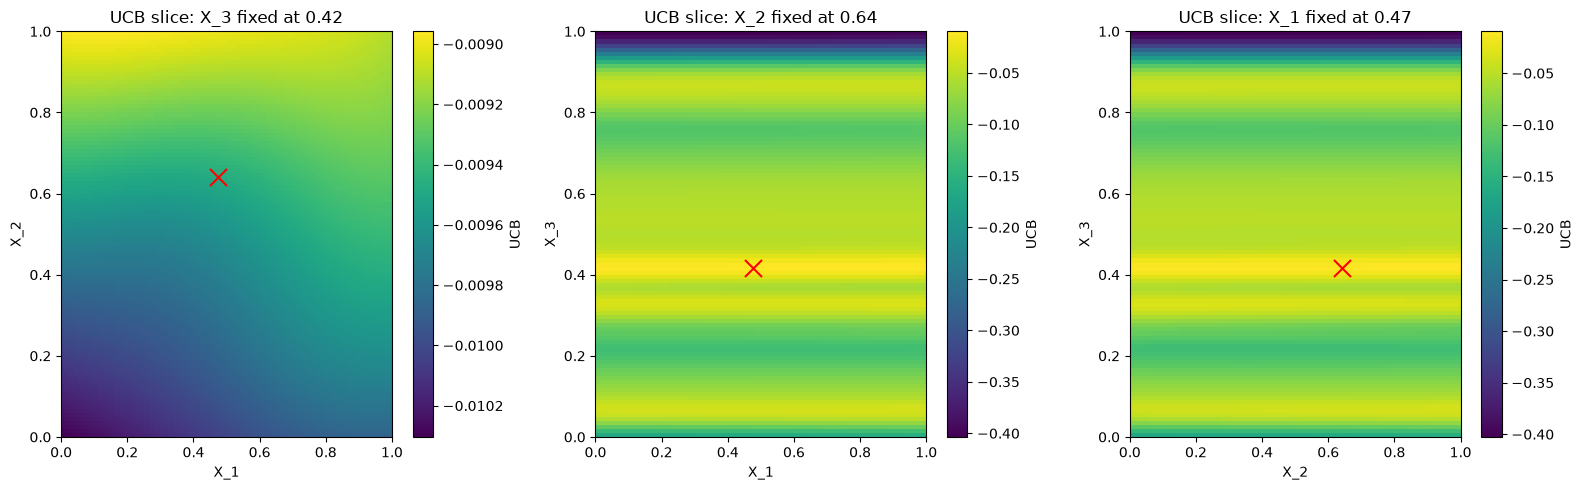

In [116]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 10: Strategy - Continuing to Tighten the Local Search

In [119]:
current_best_x = X[np.argmax(Y)]
delta          = 0.05  # WEEK 10 CHANGE: tightened from 0.08
lower_bound    = np.clip(current_best_x - delta, 0, 1)
upper_bound    = np.clip(current_best_x + delta, 0, 1)
print(f"Current best point: {current_best_x}")
print(f"Local search bounds: lower={lower_bound}, upper={upper_bound}")

n_candidates = 50000
candidates   = np.random.uniform(lower_bound, upper_bound, size=(n_candidates, 3))

mu, std = gpr.predict(candidates, return_std=True)

beta = 0.15  # lowered from 0.2, near-pure exploitation around the confirmed best region
ucb  = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"\nSuggested next Query Point (Week 10, tightest local search yet): {next_point}")
print(f"Predicted Mean(mu): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (sigma): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Current best point: [0.411697 0.562131 0.417491]
Local search bounds: lower=[0.361697 0.512131 0.367491], upper=[0.461697 0.612131 0.467491]

Suggested next Query Point (Week 10, tightest local search yet): [0.42956892 0.61079098 0.41682272]
Predicted Mean(mu): -1.120602e-02
Predicted Std (sigma): 8.418269e-03
UCB Score: -9.943282e-03


# Week 10: UCB Landscape Visualisation

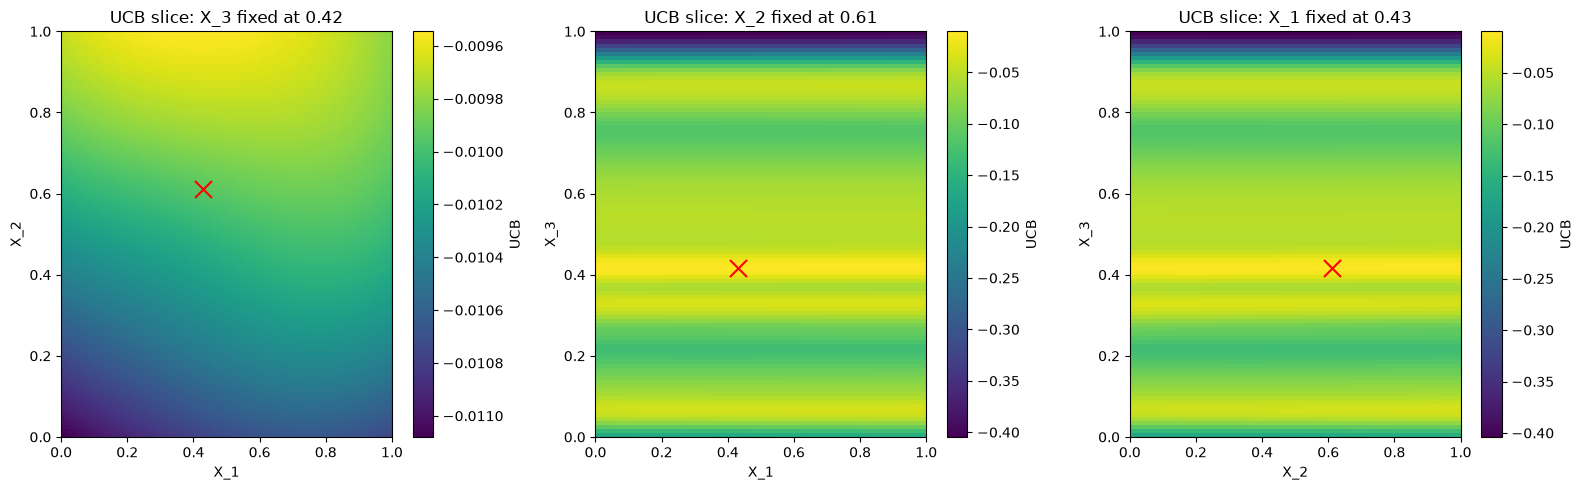

In [122]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 11: Strategy - Holding the Search Box, Hedging with Slightly More Exploration

**Reason:** Week 10's query (from tightening to +/-0.05) scored y = -0.010100 - **worse** than Week 9's best of -0.003963, the first regression since Week 7. The GP had predicted -0.0025 +/- 0.0033 there, so this is a real miss, not just an underestimate. However, the point still sits well inside the same compound_1/2-moderate neighbourhood as every recent best result (see the clustering analysis below), so this reads as local noise or a small bump in an otherwise flat-ish region, not evidence the neighbourhood itself is wrong. With only **one query left after this one** (Week 12 is the final submission), the response is deliberately conservative: keep the search box the same size (+/-0.05, not tightened further - there is little value in
tightening around a point that was just beaten) and nudge beta back up slightly (0.15 -> 0.2) to hedge with a bit more exploration within the box, rather than committing the second-to-last query to an even narrower bet.

In [125]:
# Box size kept the same as Week 10 (not tightened further), beta raised slightly to hedge
current_best_x = X[np.argmax(Y)]
delta          = 0.05  # WEEK 11 CHANGE: kept at Week 10's value rather than tightening again
lower_bound    = np.clip(current_best_x - delta, 0, 1)
upper_bound    = np.clip(current_best_x + delta, 0, 1)
print(f"Current best point: {current_best_x}")
print(f"Local search bounds: lower={lower_bound}, upper={upper_bound}")

n_candidates = 50000
candidates   = np.random.uniform(lower_bound, upper_bound, size=(n_candidates, 3))

mu, std = gpr.predict(candidates, return_std=True)

beta = 0.2  # WEEK 11 CHANGE: raised from 0.15, hedging after Week 10's regression
ucb  = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"\nSuggested next Query Point (Week 11): {next_point}")
print(f"Predicted Mean(mu): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (sigma): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Current best point: [0.411697 0.562131 0.417491]
Local search bounds: lower=[0.361697 0.512131 0.367491], upper=[0.461697 0.612131 0.467491]

Suggested next Query Point (Week 11): [0.44157048 0.61163809 0.41675922]
Predicted Mean(mu): -1.120046e-02
Predicted Std (sigma): 8.414914e-03
UCB Score: -9.517482e-03


# Week 11: UCB Landscape Visualisation

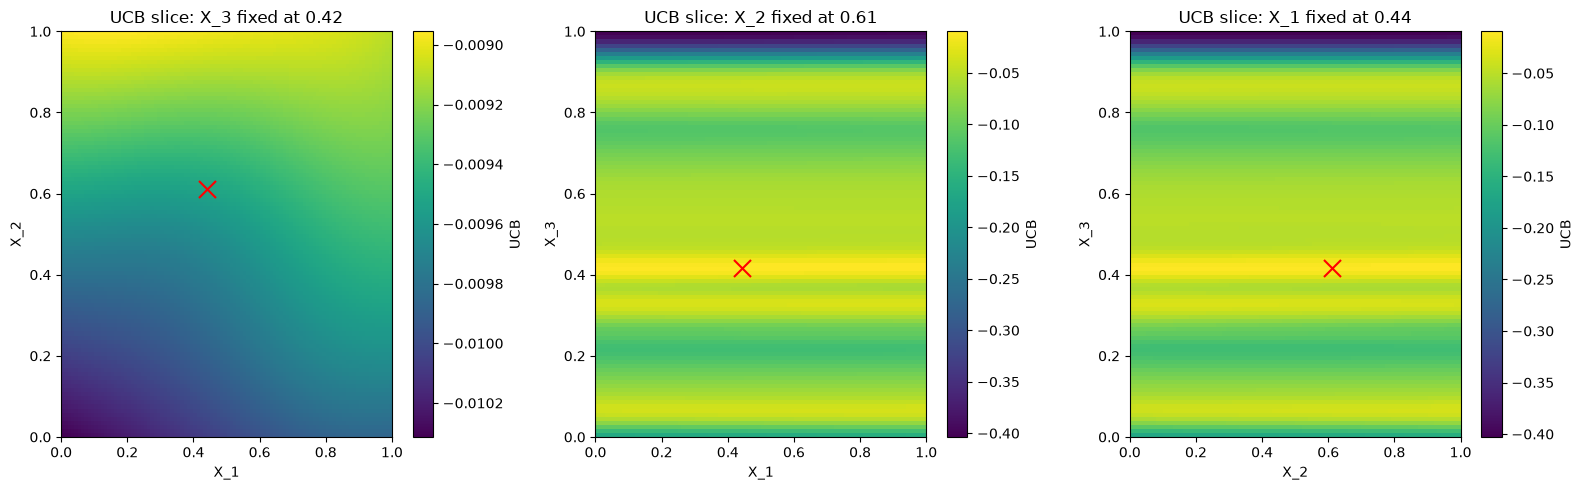

In [128]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 11: Clustering Analysis of the Weekly Queried Points

This week's reflection asks specifically about clusters and recurring regions in the search space. Rather than answer that impressionistically, this section runs **KMeans** directly on the 10 weekly queried points (not the initial 15, which were not chosen by this strategy) to check, quantitatively, whether the search has actually converged on a distinct region, and how clean that separation is from the points that were deliberately explored and discarded.

=== KMeans (k=2) over the 10 weekly query points ===
  Cluster 0: ['Week 1', 'Week 3', 'Week 4', 'Week 5', 'Week 6', 'Week 7'], mean y = -0.0572
  Cluster 1: ['Week 2', 'Week 8', 'Week 9', 'Week 10'], mean y = -0.0499

=== KMeans (k=3) over the 10 weekly query points ===
  Cluster 0: ['Week 1', 'Week 3', 'Week 4', 'Week 6', 'Week 7'], mean y = -0.0621, y values = [-0.0498 -0.0555 -0.0825 -0.0549 -0.0679]
  Cluster 1: ['Week 5', 'Week 8', 'Week 9', 'Week 10'], mean y = -0.0148, y values = [-0.0325 -0.0125 -0.004  -0.0101]
  Cluster 2: ['Week 2'], mean y = -0.1731, y values = [-0.1731]


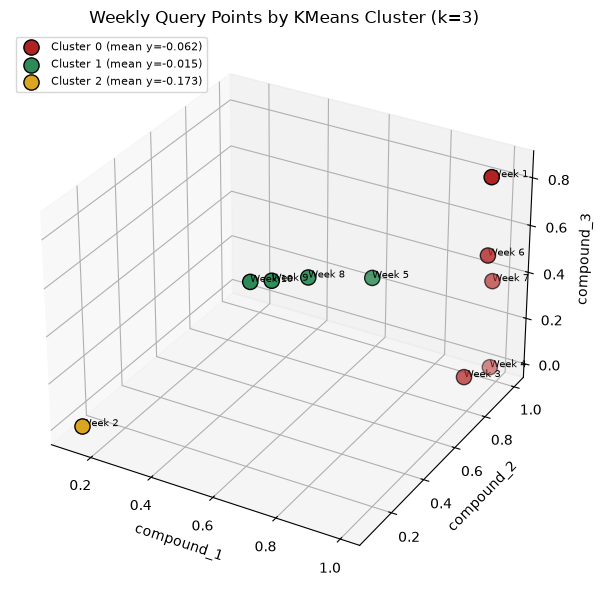


Best-performing cluster: Cluster 1 (['Week 5', 'Week 8', 'Week 9', 'Week 10']), mean y = -0.0148
This is the 'good region' the local search has been exploiting since Week 5/8.


In [131]:
# Clustering analysis - identify the "good region" vs. discarded exploration
from sklearn.cluster import KMeans

weekly_X = np.vstack([X_w1_new_point, X_w2_new_point, X_w3_new_point, X_w4_new_point,
                       X_w5_new_point, X_w6_new_point, X_w7_new_point, X_w8_new_point,
                       X_w9_new_point, X_w10_new_point])
weekly_Y = np.array([Y_w1_new_point[0], Y_w2_new_point[0], Y_w3_new_point[0], Y_w4_new_point[0],
                      Y_w5_new_point[0], Y_w6_new_point[0], Y_w7_new_point[0], Y_w8_new_point[0],
                      Y_w9_new_point[0], Y_w10_new_point[0]])
week_names = [f"Week {i+1}" for i in range(10)]

print("=== KMeans (k=2) over the 10 weekly query points ===")
km2 = KMeans(n_clusters=2, random_state=0, n_init=10).fit(weekly_X)
for lab in sorted(set(km2.labels_)):
    idx = np.where(km2.labels_ == lab)[0]
    print(f"  Cluster {lab}: {[week_names[i] for i in idx]}, mean y = {weekly_Y[idx].mean():.4f}")

print("\n=== KMeans (k=3) over the 10 weekly query points ===")
km3 = KMeans(n_clusters=3, random_state=0, n_init=10).fit(weekly_X)
cluster_summary = []
for lab in sorted(set(km3.labels_)):
    idx = np.where(km3.labels_ == lab)[0]
    mean_y = weekly_Y[idx].mean()
    cluster_summary.append((lab, idx, mean_y))
    print(f"  Cluster {lab}: {[week_names[i] for i in idx]}, mean y = {mean_y:.4f}, "
          f"y values = {weekly_Y[idx].round(4)}")

# 3D scatter colored by cluster assignment, so the separation is visible, not just printed
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
cluster_colors = ["firebrick", "seagreen", "goldenrod"]
for lab in sorted(set(km3.labels_)):
    idx = np.where(km3.labels_ == lab)[0]
    ax.scatter(weekly_X[idx, 0], weekly_X[idx, 1], weekly_X[idx, 2],
               c=cluster_colors[lab % len(cluster_colors)], s=120, edgecolor="black",
               label=f"Cluster {lab} (mean y={weekly_Y[idx].mean():.3f})")
    for i in idx:
        ax.text(weekly_X[i, 0], weekly_X[i, 1], weekly_X[i, 2], week_names[i], fontsize=7)
ax.set_xlabel("compound_1"); ax.set_ylabel("compound_2"); ax.set_zlabel("compound_3")
ax.set_title("Weekly Query Points by KMeans Cluster (k=3)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

best_cluster = max(cluster_summary, key=lambda c: c[2])
print(f"\nBest-performing cluster: Cluster {best_cluster[0]} "
      f"({[week_names[i] for i in best_cluster[1]]}), mean y = {best_cluster[2]:.4f}")
print("This is the 'good region' the local search has been exploiting since Week 5/8.")

# Week 12: Strategy - Re-centre on the New Best, Lower Betaa and add Diagnostics

**Reason:** Week 11's query (y = -0.003116) is a new best, so the local search box re-centres on it. Because that point sat near the lower edge of the old box, the new box reaches further down the compound_1/compound_2 diagonal (roughly compound_1 0.36-0.46, compound_2 0.51-0.61), which is the direction along which results have improved since Week 5. Two cautions shape the rest of the decision:

1. **Noise:** The fitted observation noise is about 0.007, the same size as the differences between the Week 9, 10 and 11 results. The GP's posterior mean at those three points is nearly identical.
2. **The GP cannot see compound_1/2 structure:** Their length-scales are pinned at the upper bound, so the model is almost flat in those directions and the suggested point tends to land on the edge of the box. That makes it a probe along a weak trend, not a located optimum.

With one query left after this, Week 12 is the last chance to learn something that can still be acted on, while the final round should be pure exploitation. beta is lowered to 0.1 (0.2 before), and the new sensitivity check below shows the selected point does not depend on beta anyway.

In [134]:
# Re-centering box on the new best automatically; beta lowered 0.2 -> 0.1; added two diagnostics
current_best_x = X[np.argmax(Y)]
delta          = 0.05  # WEEK 12 CHANGE: kept at +/-0.05 (box now centred on the Week 11 point)
lower_bound    = np.clip(current_best_x - delta, 0, 1)
upper_bound    = np.clip(current_best_x + delta, 0, 1)
print(f"Current best point: {current_best_x}")
print(f"Local search bounds: lower={lower_bound}, upper={upper_bound}")

n_candidates = 50000
candidates   = np.random.uniform(lower_bound, upper_bound, size=(n_candidates, 3))

mu, std = gpr.predict(candidates, return_std=True)

beta = 0.1  # WEEK 12 CHANGE: lowered from 0.2 ahead of the final (pure exploitation) query
ucb  = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"\nSuggested next Query Point (Week 12): {next_point}")
print(f"Predicted Mean(mu): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (sigma): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

# Diagnostic 1 - does the choice of beta matter inside this box?
print("\nBeta sensitivity (same candidates):")
for b_test in [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]:
    i_b = np.argmax(mu + b_test * std)
    print(f"  beta={b_test:<4}: {candidates[i_b].round(4)}  (mu={mu[i_b]:.5f}, sigma={std[i_b]:.5f})")

# Diagnostic 2 - is the suggested point on the box edge (a probe) or in the interior?
edge_gap = np.minimum(np.abs(next_point - lower_bound), np.abs(upper_bound - next_point))
for lab_i, gap in zip(["compound_1", "compound_2", "compound_3"], edge_gap):
    print(f"  {lab_i}: distance to nearest box edge = {gap:.4f}" + ("  <-- on the edge" if gap < 0.005 else ""))

# Checking noise (fitted WhiteKernel, converted back to y units)
noise_std = np.sqrt(gpr.kernel_.k2.noise_level) * Y.std()
print(f"\nFitted observation-noise std (y units): ~{noise_std:.4f}")
for nm, xp, yp in [("Week 9", X_w9_new_point, Y_w9_new_point), ("Week 10", X_w10_new_point, Y_w10_new_point),
                   ("Week 11", X_w11_new_point, Y_w11_new_point)]:
    m_p, s_p = gpr.predict(xp.reshape(1, -1), return_std=True)
    print(f"  {nm}: observed y = {yp[0]:.4f} | GP posterior mean there = {m_p[0]:.4f} (+/- {s_p[0]:.4f})")

Current best point: [0.411697 0.562131 0.417491]
Local search bounds: lower=[0.361697 0.512131 0.367491], upper=[0.461697 0.612131 0.467491]

Suggested next Query Point (Week 12): [0.46116669 0.60859368 0.41670678]
Predicted Mean(mu): -1.119901e-02
Predicted Std (sigma): 8.417817e-03
UCB Score: -1.035723e-02

Beta sensitivity (same candidates):
  beta=0.0 : [0.4612 0.6086 0.4167]  (mu=-0.01120, sigma=0.00842)
  beta=0.05: [0.4612 0.6086 0.4167]  (mu=-0.01120, sigma=0.00842)
  beta=0.1 : [0.4612 0.6086 0.4167]  (mu=-0.01120, sigma=0.00842)
  beta=0.2 : [0.4612 0.6086 0.4167]  (mu=-0.01120, sigma=0.00842)
  beta=0.3 : [0.4612 0.6086 0.4167]  (mu=-0.01120, sigma=0.00842)
  beta=0.5 : [0.3634 0.6119 0.4154]  (mu=-0.01132, sigma=0.00874)
  compound_1: distance to nearest box edge = 0.0005  <-- on the edge
  compound_2: distance to nearest box edge = 0.0035  <-- on the edge
  compound_3: distance to nearest box edge = 0.0492

Fitted observation-noise std (y units): ~0.0078
  Week 9: observed

# Week 12: UCB Landscape Visualisation

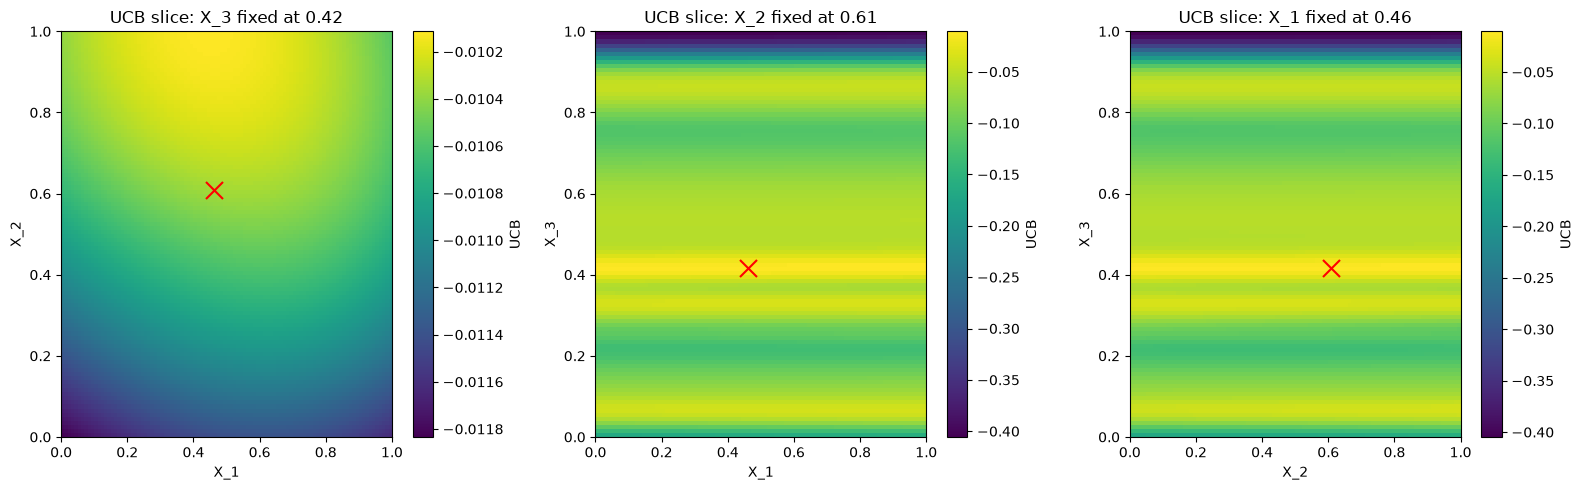

In [137]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 12: PCA - Analysing the direction which carry the variations

PCA is applied to the standardised inputs (all 26 points) to see how many independent directions the sampled space really has, and how that lines up with what the GP's length-scales say. Note the limit: PCA measures where the
queries vary, not what changes the output, so it is read next to the GP length-scales and the top results rather than on its own.

Explained variance ratio: [0.573 0.331 0.096] | cumulative: [0.573 0.904 1.   ]

Loadings (rows = PCs, columns = compound_1, compound_2, compound_3):
     compound_1  compound_2  compound_3
PC1      -0.704      -0.705       0.091
PC2       0.076       0.052       0.996
PC3       0.706      -0.708      -0.017

Input correlation matrix:
            compound_1  compound_2  compound_3
compound_1       1.000       0.713      -0.038
compound_2       0.713       1.000      -0.055
compound_3      -0.038      -0.055       1.000

GP length-scales: {'compound_1': np.float64(10.0), 'compound_2': np.float64(10.0), 'compound_3': np.float64(0.101)}


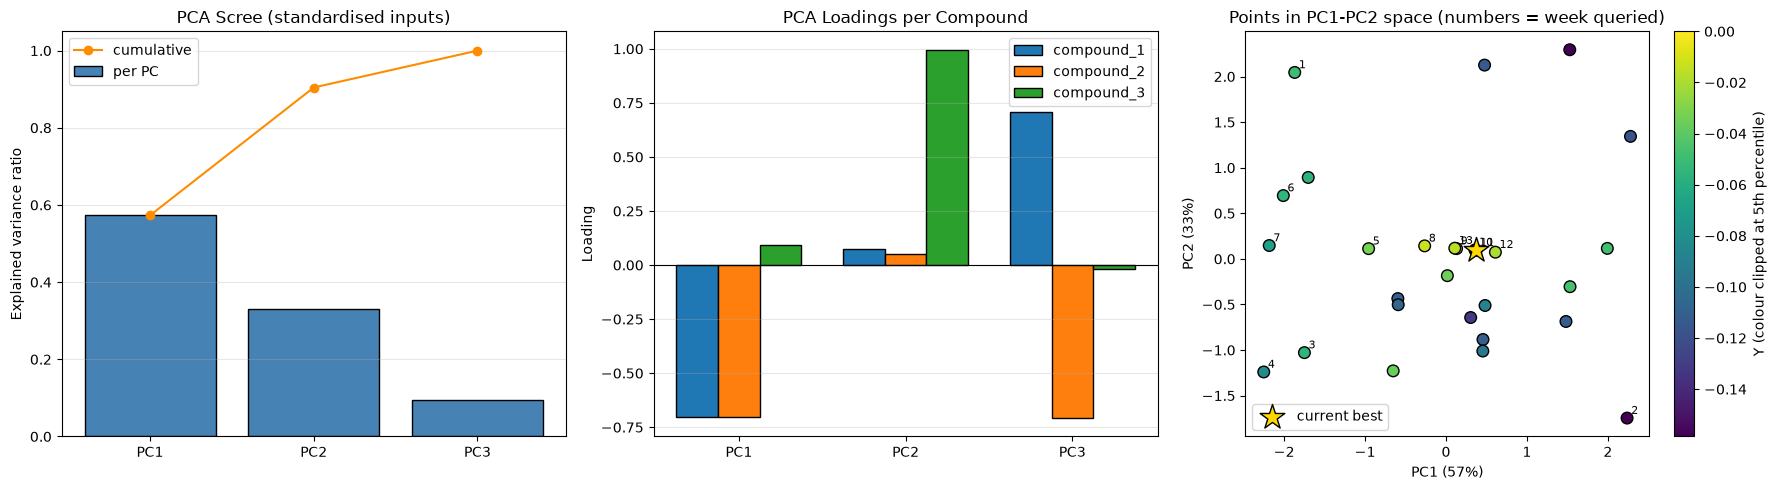


Top 5 results (compound_1, compound_2, compound_3, y):
[[ 0.4117  0.5621  0.4175 -0.0031]
 [ 0.4591  0.6087  0.4167 -0.004 ]
 [ 0.4106  0.5682  0.4183 -0.0101]
 [ 0.5388  0.6829  0.4153 -0.0125]
 [ 0.4639  0.6127  0.4173 -0.0165]]
compound_3 range among top 5: 0.415-0.418 | compound_1 range: 0.411-0.539


In [139]:
# PCA on the sampled inputs, to check redundancy between compounds
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Z_all   = StandardScaler().fit_transform(X)
pca_all = PCA().fit(Z_all)
scores  = pca_all.transform(Z_all)
pc_names = ["PC1", "PC2", "PC3"]

print("Explained variance ratio:", pca_all.explained_variance_ratio_.round(3),
      "| cumulative:", np.cumsum(pca_all.explained_variance_ratio_).round(3))
print("\nLoadings (rows = PCs, columns = compound_1, compound_2, compound_3):")
print(pd.DataFrame(pca_all.components_, index=pc_names, columns=["compound_1", "compound_2", "compound_3"]).round(3))
print("\nInput correlation matrix:")
print(pd.DataFrame(np.corrcoef(X.T), index=["compound_1", "compound_2", "compound_3"],
                   columns=["compound_1", "compound_2", "compound_3"]).round(3))

# What the GP itself says about each compound (length-scale: short = influential)
ls_vals = np.atleast_1d(gpr.kernel_.k1.k2.length_scale)
print("\nGP length-scales:", dict(zip(["compound_1", "compound_2", "compound_3"], ls_vals.round(3))))

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: scree
ax = axs[0]
ax.bar(pc_names, pca_all.explained_variance_ratio_, color="steelblue", edgecolor="black", label="per PC")
ax.plot(pc_names, np.cumsum(pca_all.explained_variance_ratio_), "o-", color="darkorange", label="cumulative")
ax.set_ylabel("Explained variance ratio"); ax.set_title("PCA Scree (standardised inputs)")
ax.legend(); ax.grid(True, axis="y", alpha=0.3)

# Panel B: loadings
ax = axs[1]
w = 0.25
for k, cname in enumerate(["compound_1", "compound_2", "compound_3"]):
    ax.bar(np.arange(3) + (k - 1) * w, pca_all.components_[:, k], width=w, label=cname, edgecolor="black")
ax.set_xticks(range(3)); ax.set_xticklabels(pc_names)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Loading"); ax.set_title("PCA Loadings per Compound"); ax.legend(); ax.grid(True, axis="y", alpha=0.3)

# Panel C: PC1 vs PC2 scores coloured by Y, weekly queries numbered, best starred
ax = axs[2]
sc_ = ax.scatter(scores[:, 0], scores[:, 1], c=Y, cmap="viridis", vmin=np.percentile(Y, 5), vmax=0,
                 s=70, edgecolor="k")
for wk in range(1, 14):   # rows 15.. are the weekly queries
    ax.annotate(str(wk), (scores[14 + wk, 0], scores[14 + wk, 1]), fontsize=8, xytext=(3, 3), textcoords="offset points")
b_i = np.argmax(Y)
ax.scatter(scores[b_i, 0], scores[b_i, 1], marker="*", s=350, c="gold", edgecolor="black", label="current best")
ax.set_xlabel(f"PC1 ({pca_all.explained_variance_ratio_[0]*100:.0f}%)")
ax.set_ylabel(f"PC2 ({pca_all.explained_variance_ratio_[1]*100:.0f}%)")
ax.set_title("Points in PC1-PC2 space (numbers = week queried)")
plt.colorbar(sc_, ax=ax, label="Y (colour clipped at 5th percentile)"); ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

# Top results: where do they sit? (this is the output-side evidence PCA alone cannot give)
top = np.argsort(Y)[-5:][::-1]
print("\nTop 5 results (compound_1, compound_2, compound_3, y):")
print(np.column_stack([X[top], Y[top]]).round(4))
print(f"compound_3 range among top 5: {X[top,2].min():.3f}-{X[top,2].max():.3f} | "
      f"compound_1 range: {X[top,0].min():.3f}-{X[top,0].max():.3f}")

# Week 13 (Final): Strategy - Use the Ridge Evidence Directly, Pure Exploitation

**What the Week 12 result showed.** The probe down the compound_1/compound_2 diagonal (compound_1 = 0.37) scored y = -0.0202, far below the Week 11 best and below the GP's own prediction. So the improvement trend does not continue past about 0.41, and the peak lies on the higher side of compound_1.

**Why the GP alone is not used to pick the final point.** Its compound_1/2 length-scales are still pinned at the upper bound, so its posterior mean is almost flat in those two directions across the good region (about -0.0101 to -0.0103 at the Week 9-11 points, against a noise std of 0.008). Its maximiser therefore moves with tiny slope changes from refit to refit, so it is a weak guide to compound_1/2, while it is reliable for compound_3 (length-scale 0.1). The GP box search is kept as a cross-check only.

**What is done instead.** The five consecutive queries of Weeks 8-12 share compound_3 of about 0.415-0.418 and lie on one line in compound_1/2. A quadratic fit of y along that line (the PC1 direction found last week) gives a peak, with leave-one-out and bootstrap checks on how stable it is. compound_3 is then set by the GP at that position. beta = 0 because there is no further query to learn for.

In [155]:
# Final query: ridge-quadratic for compound_1/2, GP for compound_3, beta = 0
# The final query was chosen when only 27 points existed. Now that Week 13 is appended (28 points), this cell refits
# the GP on the first 27 points so it still reproduces the point that was actually submitted (Matern was the LOO winner at that time).
n_pre   = 27
gpr_pre = GaussianProcessRegressor(kernel = candidate_kernels["Matern"], normalize_y = True,
                                   n_restarts_optimizer = 10, random_state = 0).fit(X[:n_pre], Y[:n_pre]) 

# --- 1. The five consecutive queries that share compound_3 of about 0.415-0.418 (Weeks 8-12) ---
ridge_X = np.vstack([X_w8_new_point, X_w9_new_point, X_w10_new_point, X_w11_new_point, X_w12_new_point])
ridge_y = np.array([Y_w8_new_point[0], Y_w9_new_point[0], Y_w10_new_point[0], Y_w11_new_point[0], Y_w12_new_point[0]])
print("compound_3 range of the ridge points:", ridge_X[:, 2].min().round(4), "-", ridge_X[:, 2].max().round(4))

# ridge line in compound_1/2 (c2 as a function of c1) and quadratic response along it
slope, intercept = np.polyfit(ridge_X[:, 0], ridge_X[:, 1], 1)
quad = np.polyfit(ridge_X[:, 0], ridge_y, 2)
assert quad[0] < 0, "quadratic is not concave - peak would be a minimum"
peak_c1 = -quad[1] / (2 * quad[0])
peak_c2 = slope * peak_c1 + intercept
peak_y  = np.polyval(quad, peak_c1)
resid   = ridge_y - np.polyval(quad, ridge_X[:, 0])
print(f"Ridge line: compound_2 = {slope:.3f} * compound_1 + {intercept:.3f}")
print(f"Quadratic peak: compound_1 = {peak_c1:.4f}, compound_2 = {peak_c2:.4f}, fitted y = {peak_y:.5f}")
print(f"Residual rms (3 dof left): {np.sqrt((resid**2).sum() / 2):.4f}")

# --- 2. How stable is the peak? leave-one-out and parametric bootstrap with the fitted noise level ---
loo_peaks = []
for j in range(5):
    keep = np.arange(5) != j
    cj = np.polyfit(ridge_X[keep, 0], ridge_y[keep], 2)
    loo_peaks.append(-cj[1] / (2 * cj[0]) if cj[0] < 0 else np.nan)
print("Leave-one-out peak compound_1:", np.round(loo_peaks, 4))

rng_boot  = np.random.RandomState(0)               # local RNG: the final point does not depend on the global random state
fitted    = np.polyval(quad, ridge_X[:, 0])
noise_std = np.sqrt(gpr.kernel_.k2.noise_level) * Y.std()
boot_peaks = []
for _ in range(5000):
    cb = np.polyfit(ridge_X[:, 0], fitted + rng_boot.normal(0, noise_std, 5), 2)
    if cb[0] < 0:
        boot_peaks.append(-cb[1] / (2 * cb[0]))
boot_peaks = np.array(boot_peaks)
print(f"Bootstrap (noise std {noise_std:.4f}): concave in {len(boot_peaks)/5000:.0%} of draws, "
      f"peak compound_1 10/50/90th percentile = {np.percentile(boot_peaks, [10, 50, 90]).round(3)}")

# --- 3. compound_3 from the GP (length-scale 0.1, so the model is informative here) at the fitted peak ---
c3_grid  = np.linspace(0.36, 0.47, 2201)
grid_pts = np.column_stack([np.full_like(c3_grid, peak_c1), np.full_like(c3_grid, peak_c2), c3_grid])
mu_c3, std_c3 = gpr.predict(grid_pts, return_std=True)
peak_c3  = c3_grid[np.argmax(mu_c3)]

beta       = 0.0   # WEEK 13 CHANGE: pure exploitation, there is no later query to learn for
next_point = np.array([peak_c1, peak_c2, peak_c3])
mu_final, std_final = gpr.predict(next_point.reshape(1, -1), return_std=True)
print(f"\nFINAL query point: {next_point.round(6)}")
print(f"GP posterior mean there: {mu_final[0]:.5f} (+/- {std_final[0]:.5f}); ridge-quadratic prediction: {peak_y:.5f}")

# --- 4. Cross-check: what would the old box search (+/-0.05 around the best observed point, beta = 0) have picked? ---
current_best_x = X[:n_pre][np.argmax(Y[:n_pre])] 
lower_bound    = np.clip(current_best_x - 0.05, 0, 1)
upper_bound    = np.clip(current_best_x + 0.05, 0, 1)
cand_check     = np.random.RandomState(1).uniform(lower_bound, upper_bound, size=(50000, 3))
mu_chk, std_chk = gpr.predict(cand_check, return_std=True)
gp_pick        = cand_check[np.argmax(mu_chk)]
print(f"GP-only box search would pick: {gp_pick.round(4)} (mu = {mu_chk.max():.5f}) - "
      f"distance from the final point: {np.linalg.norm(gp_pick - next_point):.3f}")
print(f"GP posterior-mean spread over the whole box: {mu_chk.min():.5f} to {mu_chk.max():.5f} "
      f"(range of the GP mean over the box; the top is within noise {noise_std:.4f} of the final point)")

compound_3 range of the ridge points: 0.4153 - 0.4183
Ridge line: compound_2 = 0.966 * compound_1 + 0.164
Quadratic peak: compound_1 = 0.4639, compound_2 = 0.6127, fitted y = -0.00244
Residual rms (3 dof left): 0.0037
Leave-one-out peak compound_1: [0.4451 0.464  0.462  0.4678 0.4576]
Bootstrap (noise std 0.0078): concave in 95% of draws, peak compound_1 10/50/90th percentile = [0.442 0.463 0.495]

FINAL query point: [0.463877 0.612656 0.41675 ]
GP posterior mean there: -0.01119 (+/- 0.00842); ridge-quadratic prediction: -0.00244
GP-only box search would pick: [0.445  0.612  0.4168] (mu = -0.01120) - distance from the final point: 0.019
GP posterior-mean spread over the whole box: -0.06262 to -0.01120 (range of the GP mean over the box; the top is within noise 0.0078 of the final point)


# Week 13 (Final): UCB Landscape Visualisation

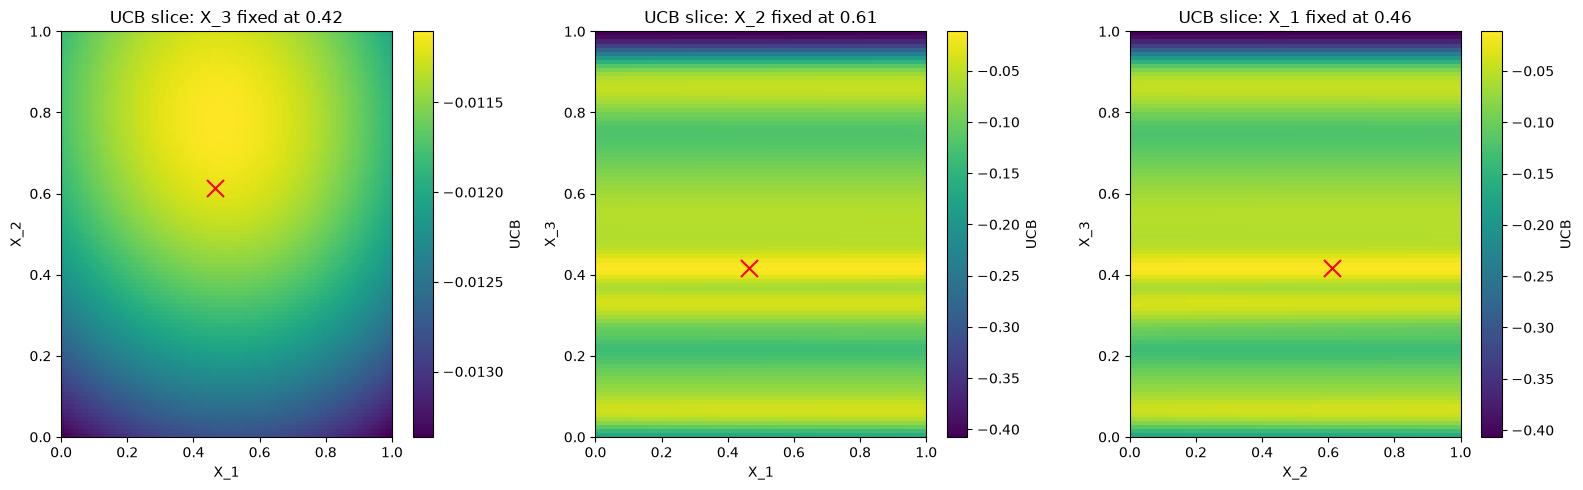

In [157]:
grid_res   = 100
lin        = np.linspace(0, 1, grid_res)
pairs      = [(0, 1, 2), (0, 2, 1), (1, 2, 0)]  # (dim_x, dim_y, dim_fixed)

fig, axes  = plt.subplots(1, 3, figsize=(16, 5))
for ax, (dx, dy, dfixed) in zip(axes, pairs):
    gx, gy                 = np.meshgrid(lin, lin)
    grid_points            = np.zeros((grid_res * grid_res, 3))
    grid_points[:, dx]     = gx.ravel()
    grid_points[:, dy]     = gy.ravel()
    grid_points[:, dfixed] = next_point[dfixed]

    mu_grid, std_grid      = gpr.predict(grid_points, return_std = True)
    ucb_grid               = (mu_grid + beta * std_grid).reshape(grid_res, grid_res)

    im                     = ax.imshow(ucb_grid, origin = "lower", extent = [0, 1, 0, 1], cmap = "viridis", aspect = "auto")
    ax.set_xlabel(labels[dx]); ax.set_ylabel(labels[dy])
    ax.set_title(f"UCB slice: {labels[dfixed]} fixed at {next_point[dfixed]:.2f}")
    ax.scatter(next_point[dx], next_point[dy], c = "red", marker = "x", s = 150, edgecolor = "black")
    plt.colorbar(im, ax = ax, label = "UCB")

plt.tight_layout()
plt.show()

# Week 13: Ridge Fit - Where Along the Diagonal Is the Peak?

The final point comes from the response along the compound_1/2 ridge (the PC1 direction), so this plot shows the evidence behind it: the five ridge points, the fitted quadratic, how much the fitted peak moves when any one point is dropped, the bootstrap spread, and the points that the GP-only search would have chosen.

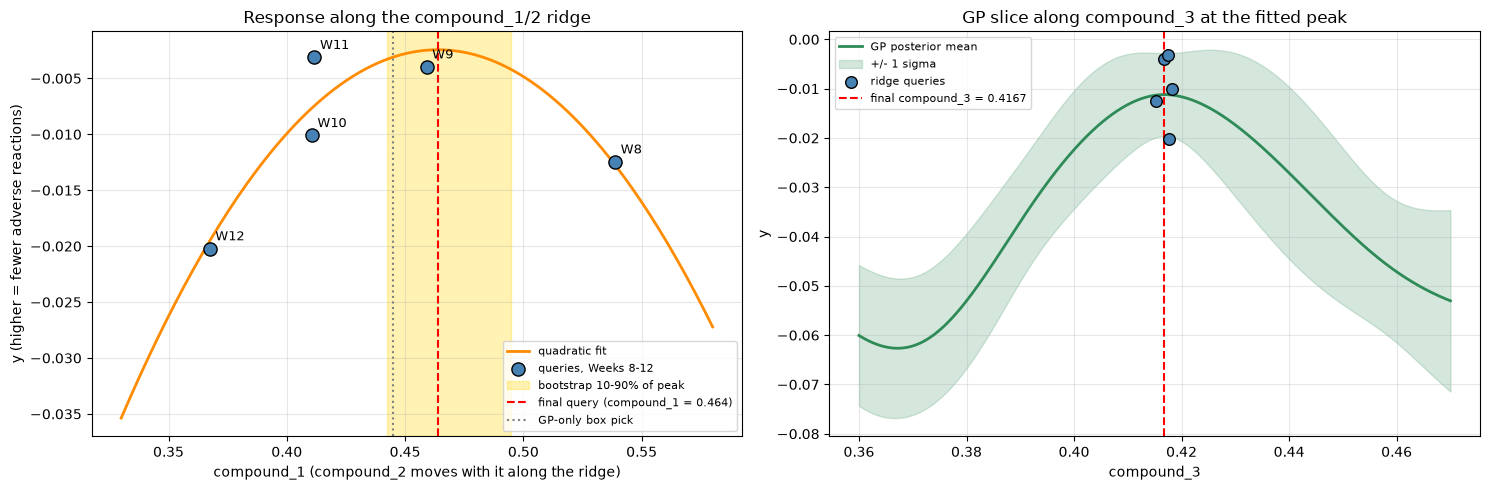

In [161]:
# Visualise the ridge fit behind the final query
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: y versus compound_1 along the ridge
ax = axs[0]
xs = np.linspace(0.33, 0.58, 200)
ax.plot(xs, np.polyval(quad, xs), color="darkorange", linewidth=2, label="quadratic fit")
ax.scatter(ridge_X[:, 0], ridge_y, c="steelblue", s=90, edgecolor="black", zorder=3, label="queries, Weeks 8-12")
for k, wk in enumerate([8, 9, 10, 11, 12]):
    ax.annotate(f"W{wk}", (ridge_X[k, 0], ridge_y[k]), xytext=(4, 6), textcoords="offset points", fontsize=9)
lo_b, hi_b = np.percentile(boot_peaks, [10, 90])
ax.axvspan(lo_b, hi_b, color="gold", alpha=0.3, label="bootstrap 10-90% of peak")
ax.axvline(peak_c1, color="red", linestyle="--", label=f"final query (compound_1 = {peak_c1:.3f})")
ax.axvline(gp_pick[0], color="gray", linestyle=":", label="GP-only box pick")
ax.set_xlabel("compound_1 (compound_2 moves with it along the ridge)")
ax.set_ylabel("y (higher = fewer adverse reactions)")
ax.set_title("Response along the compound_1/2 ridge")
ax.legend(fontsize=8, loc="lower right"); ax.grid(True, alpha=0.3)

# Panel B: GP posterior mean and +/-1 sigma against compound_3 at the fitted peak
ax = axs[1]
ax.plot(c3_grid, mu_c3, color="seagreen", linewidth=2, label="GP posterior mean")
ax.fill_between(c3_grid, mu_c3 - std_c3, mu_c3 + std_c3, color="seagreen", alpha=0.2, label="+/- 1 sigma")
ax.scatter(ridge_X[:, 2], ridge_y, c="steelblue", s=70, edgecolor="black", zorder=3, label="ridge queries")
ax.axvline(peak_c3, color="red", linestyle="--", label=f"final compound_3 = {peak_c3:.4f}")
ax.set_xlabel("compound_3"); ax.set_ylabel("y")
ax.set_title("GP slice along compound_3 at the fitted peak")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Week 13: Analysing Output

The final query `[0.463877, 0.612656, 0.4173]` returned **y = -0.016509**. That is worse than the Week 11 best (-0.003116), so the final answer
is still the Week 11 point. The cell below compares the result with what the two models predicted, refits the ridge with the new point, and
checks how large the miss is against the observation noise.

Actual Week 13 result            : -0.01651
Ridge-quadratic predicted        : -0.00244  -> miss -0.01407 = -1.8 noise std
GP (27-point fit) predicted      : -0.01119 +/- 0.00842  -> miss -0.00532 = -0.7 noise std
Best observed (Week 11)          : -0.00312  -> Week 13 is -0.01339 below it
Fitted noise std (27-point fit)  : 0.0080
Rank of the Week 13 result among all 28 points: 5

Week 9 vs Week 13: distance between the points = 0.006, y = -0.0040 vs -0.0165 (difference 0.0125 = 1.6 noise std)

Post-hoc quadratic with Weeks 8-13: leading coefficient -1.101 (concave)
  peak compound_1 = 0.4620, fitted y there = -0.00739
  leave-one-out peaks: [0.426 0.461 0.462 0.473   nan 0.464]
  residual rms (3 dof left) = 0.0072 vs fitted noise 0.0080

28-point GP at the final point: mean -0.0112 +/- 0.0084  (actual -0.0165)


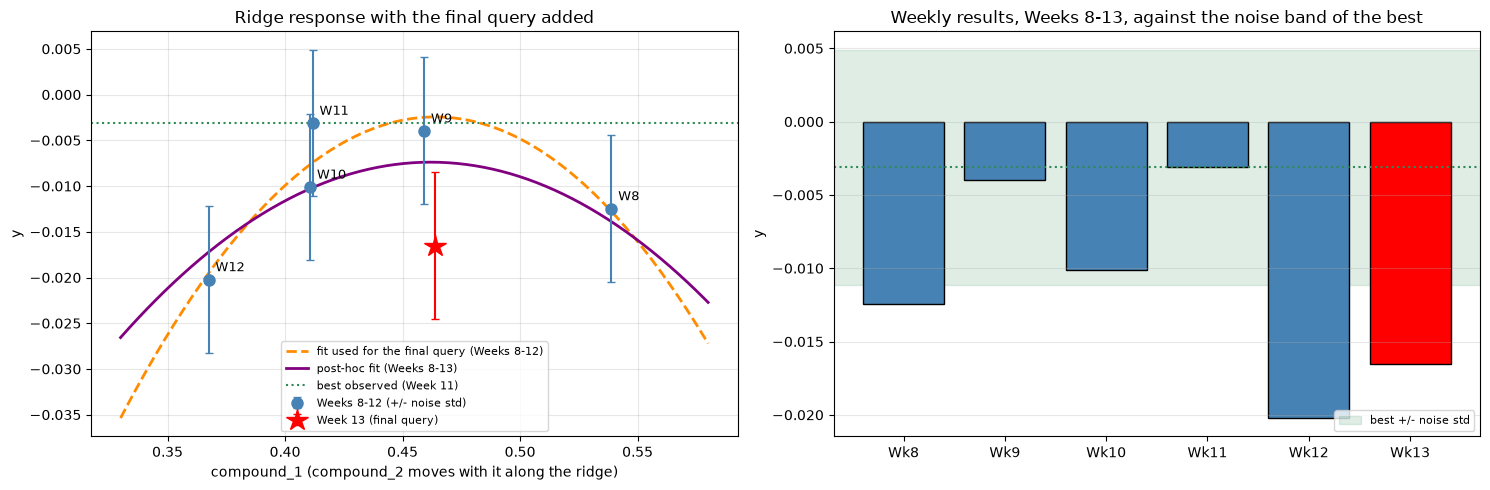

In [164]:
#  Week 13 outcome: prediction vs actual, noise comparison, post-hoc ridge refit
actual13   = Y_w13_new_point[0]
noise_pre  = np.sqrt(gpr_pre.kernel_.k2.noise_level) * Y[:27].std()      # noise level the model had when the query was chosen
best_pre   = Y[:27].max()

print(f"Actual Week 13 result            : {actual13:.5f}")
print(f"Ridge-quadratic predicted        : {peak_y:.5f}  -> miss {actual13 - peak_y:+.5f} = {(actual13 - peak_y) / noise_pre:+.1f} noise std")
print(f"GP (27-point fit) predicted      : {mu_final[0]:.5f} +/- {std_final[0]:.5f}  -> miss {actual13 - mu_final[0]:+.5f} = {(actual13 - mu_final[0]) / noise_pre:+.1f} noise std")
print(f"Best observed (Week 11)          : {best_pre:.5f}  -> Week 13 is {actual13 - best_pre:+.5f} below it")
print(f"Fitted noise std (27-point fit)  : {noise_pre:.4f}")
print(f"Rank of the Week 13 result among all {len(Y)} points: {int((Y > actual13).sum()) + 1}")

# Week 9 sits at almost the same place as Week 13 - how different were the two results?
d_9_13 = np.linalg.norm(X_w13_new_point - X_w9_new_point)
print(f"\nWeek 9 vs Week 13: distance between the points = {d_9_13:.3f}, y = {Y_w9_new_point[0]:.4f} vs {actual13:.4f} "
      f"(difference {abs(actual13 - Y_w9_new_point[0]):.4f} = {abs(actual13 - Y_w9_new_point[0]) / noise_pre:.1f} noise std)")

# Post-hoc ridge refit with Weeks 8-13 (6 points)
ridge6_X = np.vstack([ridge_X, X_w13_new_point]); ridge6_y = np.append(ridge_y, actual13)
quad6    = np.polyfit(ridge6_X[:, 0], ridge6_y, 2)
print("\nPost-hoc quadratic with Weeks 8-13: leading coefficient", f"{quad6[0]:.3f}",
      "(concave)" if quad6[0] < 0 else "(NOT concave - no interior peak)")
if quad6[0] < 0:
    peak6 = -quad6[1] / (2 * quad6[0])
    print(f"  peak compound_1 = {peak6:.4f}, fitted y there = {np.polyval(quad6, peak6):.5f}")
    loo6 = []
    for j in range(6):
        k6 = np.arange(6) != j
        c6 = np.polyfit(ridge6_X[k6, 0], ridge6_y[k6], 2)
        loo6.append(-c6[1] / (2 * c6[0]) if c6[0] < 0 else np.nan)
    print("  leave-one-out peaks:", np.round(loo6, 3))
res6 = ridge6_y - np.polyval(quad6, ridge6_X[:, 0])
print(f"  residual rms (3 dof left) = {np.sqrt((res6**2).sum() / 3):.4f} vs fitted noise {noise_pre:.4f}")

# What the 28-point GP (the one used by the rest of the notebook) says at the final point
m28, s28 = gpr.predict(X_w13_new_point.reshape(1, -1), return_std=True)
print(f"\n28-point GP at the final point: mean {m28[0]:.4f} +/- {s28[0]:.4f}  (actual {actual13:.4f})")

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
ax = axs[0]
xs = np.linspace(0.33, 0.58, 200)
ax.plot(xs, np.polyval(quad, xs), color="darkorange", linewidth=2, linestyle="--", label="fit used for the final query (Weeks 8-12)")
ax.plot(xs, np.polyval(quad6, xs), color="purple", linewidth=2, label="post-hoc fit (Weeks 8-13)")
ax.errorbar(ridge_X[:, 0], ridge_y, yerr=noise_pre, fmt="o", color="steelblue", markersize=8, capsize=3, label="Weeks 8-12 (+/- noise std)")
for k, wk in enumerate([8, 9, 10, 11, 12]):
    ax.annotate(f"W{wk}", (ridge_X[k, 0], ridge_y[k]), xytext=(5, 6), textcoords="offset points", fontsize=9)
ax.errorbar([X_w13_new_point[0]], [actual13], yerr=noise_pre, fmt="*", color="red", markersize=16, capsize=3, label="Week 13 (final query)")
ax.axhline(best_pre, color="seagreen", linestyle=":", label="best observed (Week 11)")
ax.set_xlabel("compound_1 (compound_2 moves with it along the ridge)"); ax.set_ylabel("y")
ax.set_title("Ridge response with the final query added"); ax.legend(fontsize=8, loc="lower center"); ax.grid(True, alpha=0.3)

ax = axs[1]
wk_idx  = np.arange(8, 14)
wk_y    = np.array([Y_w8_new_point[0], Y_w9_new_point[0], Y_w10_new_point[0], Y_w11_new_point[0], Y_w12_new_point[0], actual13])
ax.axhspan(best_pre - noise_pre, best_pre + noise_pre, color="seagreen", alpha=0.15, label="best +/- noise std")
ax.bar(wk_idx, wk_y, color=["steelblue"] * 5 + ["red"], edgecolor="black")
ax.axhline(best_pre, color="seagreen", linestyle=":")
ax.set_xticks(wk_idx); ax.set_xticklabels([f"Wk{w}" for w in wk_idx])
ax.set_ylabel("y"); ax.set_title("Weekly results, Weeks 8-13, against the noise band of the best")
ax.legend(fontsize=8, loc="lower right"); ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Portal Submission 

In [166]:
# Format as required by the capstone portal: x1-x2 (6 decimal places)
submission_str = f"{next_point[0]:.6f}-{next_point[1]:.6f}-{next_point[2]:.6f}"
print("Points to be submitted (Week 1) :", '0.989736-0.937592-0.849609')
print("Points to be submitted (Week 2) :", '0.130658-0.076877-0.000068')
print("Points to be submitted (Week 3) :", '0.990706-0.795157-0.087796')
print("Points to be submitted (Week 4) :", '0.969416-0.964611-0.393406')  
print("Points to be submitted (Week 5) :", '0.683102-0.806806-0.392104') 
print("Points to be submitted (Week 6) :", '0.981431-0.950647-0.511337') 
print("Points to be submitted (Week 7) :", '0.977494-0.997588-0.372098')
print("Points to be submitted (Week 8) :", '0.538784-0.682926-0.415306')
print("Points to be submitted (Week 9) :", '0.459096-0.608722-0.416672')
print("Points to be submitted (Week 10):", '0.410604-0.568193-0.418252')
print("Points to be submitted (Week 11):", '0.411697-0.562131-0.417491')
print("Points to be submitted (Week 12):", '0.367441-0.513997-0.417681')
print("Points to be submitted (Week 13):", '0.463877-0.612656-0.417300')
#print("Points to be submitted (Week 13):", submission_str) 

Points to be submitted (Week 1) : 0.989736-0.937592-0.849609
Points to be submitted (Week 2) : 0.130658-0.076877-0.000068
Points to be submitted (Week 3) : 0.990706-0.795157-0.087796
Points to be submitted (Week 4) : 0.969416-0.964611-0.393406
Points to be submitted (Week 5) : 0.683102-0.806806-0.392104
Points to be submitted (Week 6) : 0.981431-0.950647-0.511337
Points to be submitted (Week 7) : 0.977494-0.997588-0.372098
Points to be submitted (Week 8) : 0.538784-0.682926-0.415306
Points to be submitted (Week 9) : 0.459096-0.608722-0.416672
Points to be submitted (Week 10): 0.410604-0.568193-0.418252
Points to be submitted (Week 11): 0.411697-0.562131-0.417491
Points to be submitted (Week 12): 0.367441-0.513997-0.417681
Points to be submitted (Week 13): 0.463877-0.612656-0.417300


# Plot the Progress of the optimisation process

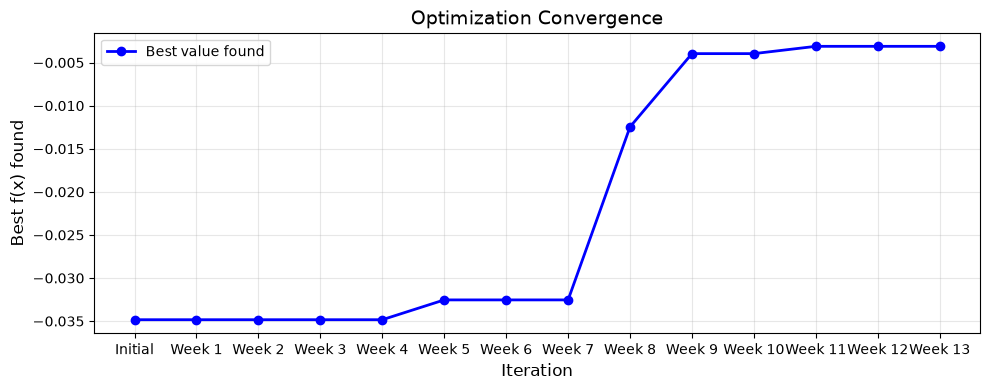

Best value found so far: -0.003116136966901461


In [170]:
# Track best-value-found progress across weeks
best_so_far = [
    -0.034835313350078584,                                 # best after initial 15 points
    max(-0.034835313350078584, -0.04976805147714386),      # best after Week 1
    max(-0.034835313350078584, -0.17308602208694687),      # best after Week 2
    max(-0.034835313350078584, -0.05549717617041605),      # best after Week 3 (corrected)
    max(-0.034835313350078584, -0.082473716892482),        # best after Week 4  
    max(-0.034835313350078584, -0.03253700291950847),      # best after Week 5
    max(-0.03253700291950847,  -0.054925397272106755),     # best after Week 6
    max(-0.03253700291950847,  -0.06792216897886878),      # best after Week 7
    max(-0.03253700291950847,  -0.012460149936303126),     # best after Week 8
    max(-0.012460149936303126, -0.003963060182358778),     # best after Week 9
    max(-0.003963060182358778, -0.010100240618389834),     # best after Week 10
    max(-0.003963060182358778, -0.003116136966901461),     # best after Week 11
    max(-0.003116136966901461, -0.02022025548644341),      # best after Week 12
    max(-0.003116136966901461, -0.01650908489632887),      # best after Week 13
]

fig, ax     = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(['Initial', 'Week 1', 'Week 2', 'Week 3', 'Week 4', 'Week 5', 'Week 6'
                    , 'Week 7', 'Week 8', 'Week 9', 'Week 10', 'Week 11', 'Week 12', 'Week 13'])   
plt.show()

print("Best value found so far:", max(best_so_far))

# Weekly Results Dashboard

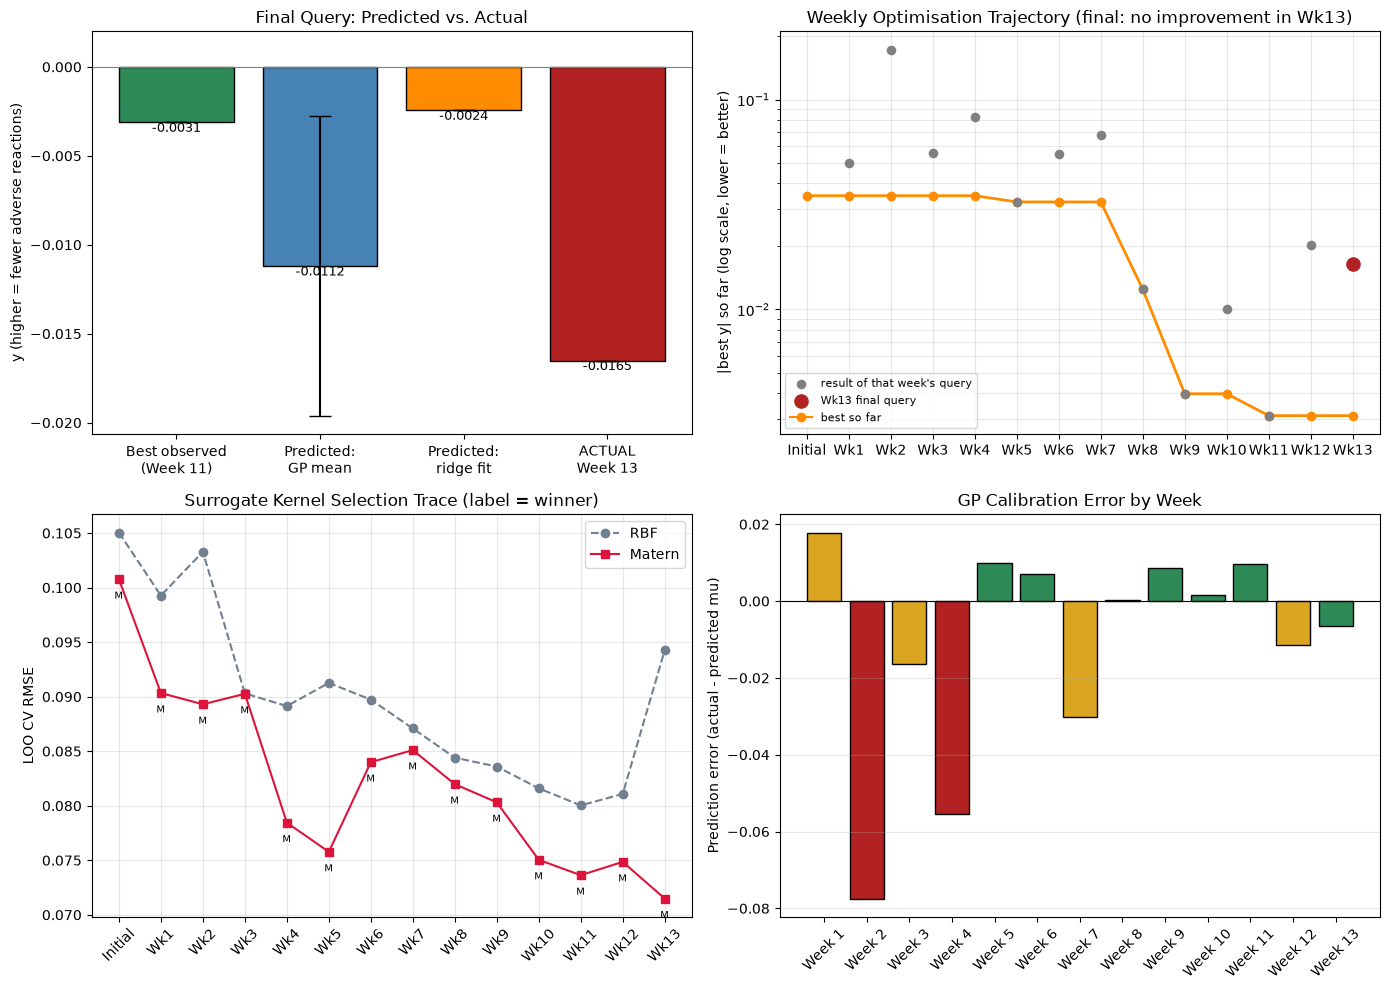

Calibration error, last 3 weeks: ['+0.0097', '-0.0114', '-0.0064'] | mean |error| = 0.0092 vs fitted observation-noise std ~0.0078 -> errors are about the size of the noise, so the GP is as accurate here as the data allows

FINAL: best observed y = -0.003116 at [0.411697 0.562131 0.417491] | Week 13 query returned -0.016509 (did not improve)


In [172]:
# 4-panel results dashboard, adapted from a cohort colleague's visualisation
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# --- Panel 1: final query - what was predicted vs what happened ---   
ax = axs[0, 0]
current_best_y = Y[:27].max()          # best of the first 27 points (Week 11), the value the final query had to beat
actual_final   = Y_w13_new_point[0]    
pred_mu, pred_std = float(mu_final[0]), float(std_final[0])
labels1 = ["Best observed\n(Week 11)", "Predicted:\nGP mean", "Predicted:\nridge fit", "ACTUAL\nWeek 13"]
vals1   = [current_best_y, pred_mu, peak_y, actual_final]
bars = ax.bar(labels1, vals1, yerr=[0, pred_std, 0, 0], capsize=8,
              color=["seagreen", "steelblue", "darkorange", "firebrick"], edgecolor="black") 
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylabel("y (higher = fewer adverse reactions)")
ax.set_title("Final Query: Predicted vs. Actual")
for b, v in zip(bars, vals1):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:.4f}", ha="center", va="top", fontsize=9)
ax.set_ylim(min(vals1) * 1.25, 0.002)

# --- Panel 2: weekly optimisation trajectory (log scale of |y|, since y<0) ---
ax = axs[0, 1]
week_labels_traj = ['Initial', 'Wk1', 'Wk2', 'Wk3', 'Wk4', 'Wk5', 'Wk6', 'Wk7', 'Wk8', 'Wk9', 'Wk10', 'Wk11', 'Wk12', 'Wk13'] 
cum_n_traj = [15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]  # <<new_final>>  # WEEK 13 CHANGE  # WEEK 12 CHANGE  # WEEK 11 CHANGE
best_so_far_local = [Y[:n].max() for n in cum_n_traj]  # WEEK 10 CHANGE: computed locally so this panel doesn't depend on a later cell
ax.plot(week_labels_traj, np.abs(best_so_far_local), 'o-', color="darkorange", linewidth=2)
ax.scatter(week_labels_traj[1:], np.abs(Y[15:28]), color="gray", s=35, zorder=3, label="result of that week's query") 
ax.scatter([week_labels_traj[-1]], [abs(Y[27])], color="firebrick", s=90, zorder=4, label="Wk13 final query")   
ax.plot([], [], 'o-', color="darkorange", label="best so far")   # legend entry only
ax.legend(fontsize=8, loc="lower left")   # <<new_final>>
ax.set_yscale("log")
ax.set_ylabel("|best y| so far (log scale, lower = better)")
ax.set_title("Weekly Optimisation Trajectory (final: no improvement in Wk13)") 
ax.grid(True, which="both", alpha=0.3)

# --- Panel 3: kernel CV RMSE trace by week, winning kernel annotated ---
ax = axs[1, 0]
cum_points = [("Initial", 15), ("Wk1", 16), ("Wk2", 17), ("Wk3", 18), ("Wk4", 19),
              ("Wk5", 20), ("Wk6", 21), ("Wk7", 22), ("Wk8", 23), ("Wk9", 24), ("Wk10", 25), ("Wk11", 26), ("Wk12", 27), ("Wk13", 28)]    # WEEK 13 CHANGE  # WEEK 12 CHANGE  # WEEK 11 CHANGE
rbf_trace, matern_trace, winners = [], [], []
for _, n in cum_points:
    Xn, Yn = X[:n], Y[:n]
    r_rbf = loo_rmse(rbf_kernel, Xn, Yn)
    r_mat = loo_rmse(matern_kernel, Xn, Yn)
    rbf_trace.append(r_rbf); matern_trace.append(r_mat)
    winners.append("RBF" if r_rbf <= r_mat else "Matern")
x_pos = np.arange(len(cum_points))
ax.plot(x_pos, rbf_trace, 'o--', label="RBF", color="slategray")
ax.plot(x_pos, matern_trace, 's-', label="Matern", color="crimson")
for xi, w in zip(x_pos, winners):
    ax.annotate(w[0], (xi, min(rbf_trace[xi], matern_trace[xi])), textcoords="offset points",
                xytext=(0, -14), ha="center", fontsize=7, color="black")
ax.set_xticks(x_pos); ax.set_xticklabels([c[0] for c in cum_points], rotation=45)
ax.set_ylabel("LOO CV RMSE")
ax.set_title("Surrogate Kernel Selection Trace (label = winner)")
ax.legend()
ax.grid(True, alpha=0.3)

# --- Panel 4: GP calibration error by week (predicted vs actual) ---
ax = axs[1, 1]
names = [r[0] for r in calibration_results]
errors = [r[4] for r in calibration_results]
colors = ["seagreen" if abs(e) < 0.01 else ("goldenrod" if abs(e) < 0.05 else "firebrick") for e in errors]
ax.bar(names, errors, color=colors, edgecolor="black")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Prediction error (actual - predicted mu)")
ax.set_title("GP Calibration Error by Week")
ax.tick_params(axis='x', rotation=45)
ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# <<new_final>> Wk11-13 errors now shown; # WEEK 11 CHANGE: the "shrinking" claim no longer holds once Week 10's miss is included - say so plainly
# WEEK 12 CHANGE: message is now computed from the numbers instead of a fixed claim
last3 = errors[-3:]
noise_std_dash = np.sqrt(gpr.kernel_.k2.noise_level) * Y.std()
print("Calibration error, last 3 weeks:", [f"{e:+.4f}" for e in last3],
      f"| mean |error| = {np.mean(np.abs(last3)):.4f} vs fitted observation-noise std ~{noise_std_dash:.4f}",
      "-> errors are about the size of the noise, so the GP is as accurate here as the data allows"
      if np.mean(np.abs(last3)) <= 1.2 * noise_std_dash else "-> errors exceed the noise level, model is missing structure")

# <<new_final>> one-line verdict for the repo
print(f"\nFINAL: best observed y = {Y.max():.6f} at {X[np.argmax(Y)].round(6)} | Week 13 query returned {Y[27]:.6f} (did not improve)")
